# Credit Card Fraud Detection — Machine Learning Benchmark

**Machine Learning Portfolio Project | Python · Scikit-learn · Imbalanced-learn · PyOD · SHAP**

## Project Overview

This project benchmarks **supervised classifiers** (Logistic Regression, Decision Tree) and **unsupervised anomaly detectors** (Isolation Forest, LOF, ECOD) for identifying rare fraudulent card transactions. It combines imbalance-aware preprocessing, group-aware data partitioning, threshold optimization, and feature-attribution analysis.

**Research question:** Which models can detect the largest fraction of frauds while keeping **precision ≥ 80% on Validation**?

**Workflow:** Data quality → grouped Train/Validation/Test split → preprocessing and imbalance strategies → model benchmarking → validation threshold selection → frozen supervised-model Test evaluation → exploratory ECOD and SHAP analyses.

**Conventions:** `0 = legitimate`, `1 = fraud`; for all continuous scores, **higher = more suspicious**.

> **Evaluation caveats:** The split is stratified and group-aware but **not chronological**. The 80% precision constraint is enforced on Validation and may not hold on Test. ECOD and SHAP are additional exploratory analyses; they are not part of the frozen supervised-model selection.

## Setup and Reproducibility

Load the project-local helpers from `src/utils.py`, set `random_state=42`, and print the main library versions. The notebook can be launched from either the repository root or the `notebooks/` directory. The 150+ MB Credit Card CSV is **not committed to Git**; instructions for obtaining it are included in the repository README.

In [1]:
from pathlib import Path
import sys
import random
import importlib

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib
import matplotlib.pyplot as plt
import scipy
import sklearn
import imblearn
import pyod
import shap

from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    precision_score,
    recall_score,
    balanced_accuracy_score,
    precision_recall_curve,
)
from imblearn.over_sampling import RandomOverSampler
from pyod.models.ecod import ECOD

# Locate repository root when run from the root directory or notebooks/.
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src" / "utils.py").is_file():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "src" / "utils.py").is_file() or not (PROJECT_ROOT / "data").is_dir():
    raise FileNotFoundError("Project directories src/ and data/ were not found.")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src import utils
importlib.reload(utils)

SEED = 42
np.random.seed(SEED)
random.seed(SEED)

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Seaborn:", sns.__version__)
print("Scikit-learn:", sklearn.__version__)
print("SciPy:", scipy.__version__)
print("Imbalanced-learn:", imblearn.__version__)
print("PyOD:", pyod.__version__)
print("SHAP:", shap.__version__)


NumPy: 2.3.4
Pandas: 2.3.3
Matplotlib: 3.10.7
Seaborn: 0.13.2
Scikit-learn: 1.9.1
SciPy: 1.16.3
Imbalanced-learn: 0.14.2
PyOD: 3.6.7
SHAP: 0.50.0


## 1. Dataset Exploration and Data Quality

The **Credit Card Fraud Detection** dataset contains highly imbalanced, anonymized transaction records. We inspect its dimensions, feature types, class distribution, and data quality before preparing the modeling partitions.

**Features:** The experiments use `V1`–`V28` and `Amount`. The `Time` column is excluded from predictive features but retained for a diagnostic analysis of the split. The target `Class` is `0` for a legitimate transaction and `1` for fraud.

In [2]:

import kagglehub

# Use the local dataset if available
credit_path = PROJECT_ROOT / "data" / "creditcard.csv"

if not credit_path.exists():
    credit_path = kagglehub.dataset_download(
        "mlg-ulb/creditcardfraud",
        path="creditcard.csv"
    )

df_credit = pd.read_csv(credit_path)

print("Dataset shape:", df_credit.shape)


100%|██████████| 66.0M/66.0M [00:02<00:00, 29.8MB/s]

Extracting zip of creditcard.csv...


Dataset shape: (284807, 31)


### 1.1 Missing Values and Exact Duplicates

We check for missing values and exact duplicate rows before modeling. Exact duplicates are reported rather than silently removed.

In [3]:

# Vérification de la qualité des données
missing, duplicates = utils.check_data_quality(df_credit)

print("Missing values:", missing.sum())
print("Columns with missing values:", (missing > 0).sum())
print("Exact duplicate rows:", duplicates)


Missing values: 0
Columns with missing values: 0
Exact duplicate rows: 1081


### 1.2 Duplicate Predictors and Conflicting Labels

We also identify duplicate predictor profiles across `V1`–`V28` and `Amount`, excluding `Time` and `Class`. If duplicated predictor profiles occur in multiple partitions, they could lead to overly optimistic evaluation. We check for groups with contradictory target labels and subsequently keep identical predictor profiles within the same data partition.

In [4]:

# Variables prédictives
X_credit = df_credit.drop(columns=["Time", "Class"])

# Doublons sur les prédicteurs
doublons_X = X_credit.duplicated()

print("Duplicate predictor profiles:", doublons_X.sum())
print("Rows involved:", X_credit.duplicated(keep=False).sum())

# Vérification des étiquettes contradictoires
conflits = df_credit.groupby(
    list(X_credit.columns)
)["Class"].nunique()

print("Groups with conflicting labels:", (conflits > 1).sum())


Duplicate predictor profiles: 9144
Rows involved: 14293
Groups with conflicting labels: 0


### 1.3 Class Imbalance

We quantify the frequency of legitimate transactions (`0`) and fraudulent transactions (`1`). Since fraud is rare, **accuracy alone is not an informative primary metric**. The analysis emphasizes Average Precision (AP), precision, recall, and the number of false alerts and missed frauds.

,Effectif,Proportion (%)
Class,,
0,284315,99.8273
1,492,0.1727


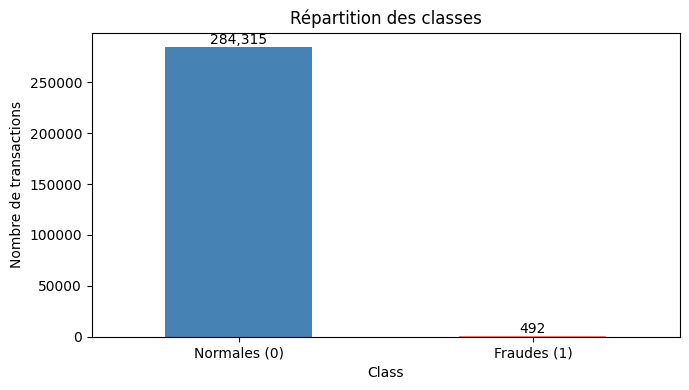

In [5]:

# Répartition des classes
counts = df_credit["Class"].value_counts().sort_index()

proportions = (
    df_credit["Class"].value_counts(normalize=True).sort_index() * 100
)

# Tableau récapitulatif
display(pd.DataFrame({
    "Effectif": counts,
    "Proportion (%)": proportions.round(4)
}))

# Visualisation
utils.plot_class_distribution(df_credit["Class"])


### 1.4 Stratified Group-Aware Train / Validation / Test Split

We split observations into approximately **60% training, 20% validation, and 20% testing**, preserving class proportions as much as the group constraints allow. Duplicate predictor profiles are assigned to a single partition.

- **Train:** Model fitting and training-only preprocessing.
- **Validation:** Hyperparameter comparison, decision-threshold tuning, and model selection.
- **Test:** Final assessment of a model and threshold selected on validation.

The random seed is fixed at `42`. We explicitly check that no predictor profile appears in more than one partition.

In [6]:

# Variables prédictives et cible
y_credit = df_credit["Class"]

# Découpage stratifié par groupes
X_train_credit, X_val_credit, X_test_credit, \
y_train_credit, y_val_credit, y_test_credit = (
    utils.split_stratified_groups(
        X_credit,
        y_credit,
        random_state=SEED
    )
)

# Vérification des partitions
for nom, X_part, y_part in [
    ("Train", X_train_credit, y_train_credit),
    ("Validation", X_val_credit, y_val_credit),
    ("Test", X_test_credit, y_test_credit)
]:
    print(
        f"{nom}: {len(X_part)} observations "
        f"({len(X_part)/len(X_credit):.2%}), "
        f"Fraudes: {y_part.sum()} ({y_part.mean():.4%})"
    )

# Vérification des doublons entre partitions
g_train = pd.MultiIndex.from_frame(X_train_credit)
g_val = pd.MultiIndex.from_frame(X_val_credit)
g_test = pd.MultiIndex.from_frame(X_test_credit)

print("\nChevauchements entre partitions :")
print("Train / Validation :", g_train.isin(g_val).sum())
print("Train / Test :", g_train.isin(g_test).sum())
print("Validation / Test :", g_val.isin(g_test).sum())


Train: 171029 observations (60.05%), Fraudes: 297 (0.1737%)
Validation: 56825 observations (19.95%), Fraudes: 100 (0.1760%)
Test: 56953 observations (20.00%), Fraudes: 95 (0.1668%)

Chevauchements entre partitions :
Train / Validation : 0
Train / Test : 0
Validation / Test : 0


**Observation:** The split produces approximately 60/20/20 partitions with similar fraud prevalence. Predictor profiles are kept out of overlapping partitions, reducing one possible source of data leakage. This is a **random**, not chronological, evaluation.

### 1.5 Temporal Limitation of the Random Split

We compare `Time` distributions across Train, Validation, and Test. This diagnostic reveals why a randomly partitioned evaluation is not equivalent to predicting **future** transactions. A chronological holdout would provide a more realistic assessment under temporal drift.

,Train,Validation,Test
min,0.0,2.0,1.0
25%,54311.0,53963.0,54122.0
50%,84950.0,84588.0,84330.0
75%,139389.0,139147.0,139289.0
max,172792.0,172786.0,172788.0


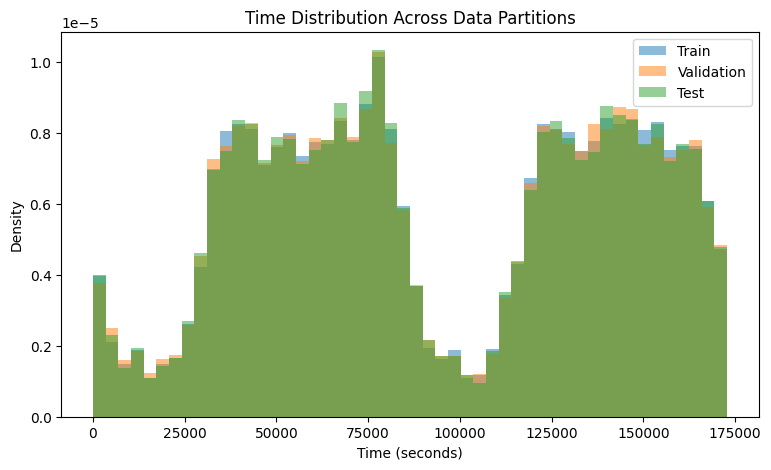

In [7]:

# Récupération de Time à partir des indices des partitions
time_train = df_credit.loc[X_train_credit.index, "Time"]
time_val = df_credit.loc[X_val_credit.index, "Time"]
time_test = df_credit.loc[X_test_credit.index, "Time"]

# Statistiques temporelles
time_stats = pd.DataFrame({
    "Train": time_train.describe(),
    "Validation": time_val.describe(),
    "Test": time_test.describe()
}).loc[["min", "25%", "50%", "75%", "max"]]

display(time_stats)

# Distribution temporelle des partitions
plt.figure(figsize=(9, 5))

plt.hist(time_train, bins=50, alpha=0.5, density=True, label="Train")
plt.hist(time_val, bins=50, alpha=0.5, density=True, label="Validation")
plt.hist(time_test, bins=50, alpha=0.5, density=True, label="Test")

plt.xlabel("Time (seconds)")
plt.ylabel("Density")
plt.title("Time Distribution Across Data Partitions")
plt.legend()
plt.show()


## 2. Feature Analysis and Preprocessing

### 2.1 Feature Scales and Distribution

Using **training data only**, we compare feature scales and inspect the distribution of `Amount`. Differences between `Amount` and the anonymized components may affect scale-sensitive models, particularly logistic regression and nearest-neighbor methods.

,mean,std,min,50%,max
V1,-0.003058,1.964310,-46.855047,0.018184,2.454930
V2,0.000880,1.632676,-47.429676,0.064788,22.057729
V3,-0.000378,1.523047,-33.680984,0.180273,4.226108
V4,-0.000109,1.419826,-5.560118,-0.022468,13.129143
V5,0.000950,1.358094,-40.427726,-0.053678,34.099309
V6,0.001327,1.319287,-23.496714,-0.272957,23.917837
V7,-0.002876,1.223557,-43.557242,0.038895,44.054461
V8,0.000562,1.200632,-50.688419,0.022702,20.007208
V9,-0.002819,1.101270,-13.434066,-0.052644,10.392889
V10,0.001729,1.093542,-24.588262,-0.091495,15.331742


,min,max,std
Amount,0.000000,11898.090000,237.907888
V1,-46.855047,2.454930,1.964310
V2,-47.429676,22.057729,1.632676
V3,-33.680984,4.226108,1.523047
V4,-5.560118,13.129143,1.419826
V5,-40.427726,34.099309,1.358094


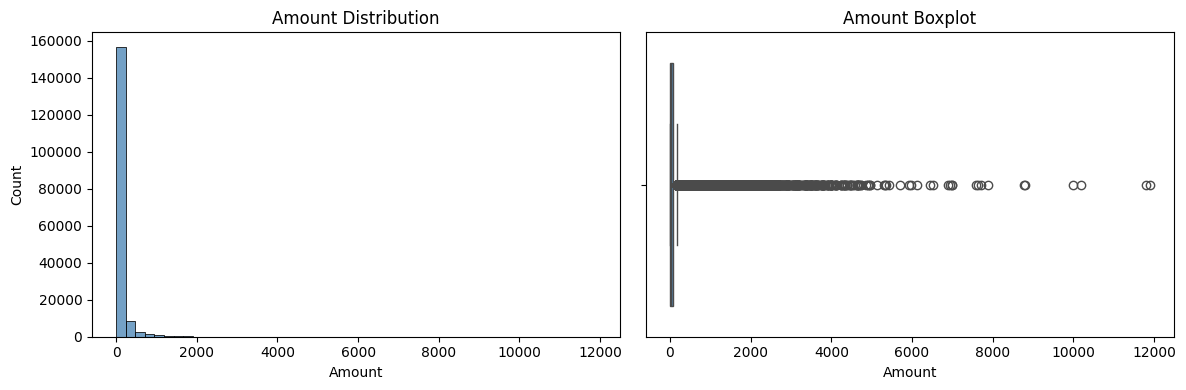

In [8]:

# Statistiques descriptives sur Train uniquement
display(
    X_train_credit.describe()
    .loc[["mean", "std", "min", "50%", "max"]]
    .T
)

# Comparaison des échelles
stats_credit = X_train_credit.agg(["min", "max", "std"]).T

display(
    stats_credit.loc[["Amount", "V1", "V2", "V3", "V4", "V5"]]
)

# Distribution de Amount
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(
    X_train_credit["Amount"],
    bins=50,
    color="steelblue",
    ax=axes[0]
)
axes[0].set_title("Amount Distribution")

sns.boxplot(
    x=X_train_credit["Amount"],
    color="steelblue",
    ax=axes[1]
)
axes[1].set_title("Amount Boxplot")

plt.tight_layout()
plt.show()


**Observation:** `Amount` is strongly right-skewed and includes large values. Its scale differs from those of the anonymized components. Scale-sensitive models therefore use training-fitted standardization; tree-based models and the selected unsupervised methods are evaluated on their specified original or standardized feature representations.

### 2.2 Standardization Without Data Leakage

We use `StandardScaler`, fitted on **Train only**, and apply the same learned transformation to Validation and Test. This prevents information from held-out data from influencing the preprocessing parameters.

In [9]:

# Standardisation des données Credit Card
X_train_credit_scaled, X_val_credit_scaled, X_test_credit_scaled, scaler_credit = (
    utils.standardize_data(
        X_train_credit,
        X_val_credit,
        X_test_credit
    )
)

# Vérification des échelles sur Train
display(
    X_train_credit_scaled[["Amount", "V1", "V2"]]
    .agg(["mean", "std"])
    .round(4)
)


,Amount,V1,V2
mean,-0.0,0.0,-0.0
std,1.0,1.0,1.0


### 2.3 Preprocessing Summary

- **Standardized features:** Logistic Regression and LOF.
- **Original features:** Decision Tree, Isolation Forest, and ECOD.
- **Excluded predictor:** `Time` (retained only for temporal diagnostics).
- **Leakage prevention:** Transformations and any oversampling are fitted **only on Train**.

The same feature order is preserved across all partitions.

## 3. Supervised Fraud Detection

We compare **Logistic Regression** and **Decision Tree** classifiers under three class-imbalance strategies:

1. **Standard:** No class rebalancing.
2. **Class weights:** `class_weight="balanced"`.
3. **Random oversampling (ROS):** Duplicate minority-class training observations using `RandomOverSampler`.

Fraud accounts for approximately **0.17%** of transactions. ROS is applied **only to Train**; Validation and Test keep their original class distributions. This experiment evaluates whether imbalance strategies improve fraud ranking and detection.

In [10]:

# Suréchantillonnage sur Train uniquement
ros_credit = RandomOverSampler(random_state=SEED)

X_train_credit_ros, y_train_credit_ros = ros_credit.fit_resample(
    X_train_credit,
    y_train_credit
)

# Application des mêmes indices aux données standardisées
X_train_credit_scaled_ros = X_train_credit_scaled.iloc[
    ros_credit.sample_indices_
].reset_index(drop=True)

# Vérification du rééquilibrage
print("Before oversampling:")
display(y_train_credit.value_counts().sort_index())

print("After oversampling:")
display(y_train_credit_ros.value_counts().sort_index())

print("Original training set:", X_train_credit.shape)
print("Oversampled training set:", X_train_credit_ros.shape)


Before oversampling:


Class
0    170732
1       297
Name: count, dtype: int64

After oversampling:


Class
0    170732
1    170732
Name: count, dtype: int64

Original training set: (171029, 29)
Oversampled training set: (341464, 29)


### 3.1 Supervised Model Configurations

We test **12 combinations**:

- Logistic Regression: `C ∈ {0.1, 1.0}` × Standard / Class Weights / ROS.
- Decision Tree: `max_depth ∈ {5, 10}` × Standard / Class Weights / ROS.

For each model, we record training time and evaluate **AP** and **ROC-AUC** on Validation, without using Test to select the model.

In [11]:

# Configurations des modèles supervisés
configurations_credit = {}

# Régression logistique : 2 valeurs de C × 3 stratégies
for C in [0.1, 1.0]:
    for variante, X_tr, y_tr, poids in [
        ("Standard", X_train_credit_scaled, y_train_credit, None),
        ("Pondération", X_train_credit_scaled, y_train_credit, "balanced"),
        ("ROS", X_train_credit_scaled_ros, y_train_credit_ros, None)
    ]:
        nom = f"LogReg - {variante} - C={C}"

        configurations_credit[nom] = (
            LogisticRegression(
                C=C,
                class_weight=poids,
                max_iter=1000,
                random_state=SEED
            ),
            X_tr,
            y_tr,
            X_val_credit_scaled
        )

# Arbre de décision : 2 profondeurs × 3 stratégies
for depth in [5, 10]:
    for variante, X_tr, y_tr, poids in [
        ("Standard", X_train_credit, y_train_credit, None),
        ("Pondération", X_train_credit, y_train_credit, "balanced"),
        ("ROS", X_train_credit_ros, y_train_credit_ros, None)
    ]:
        nom = f"Arbre - {variante} - depth={depth}"

        configurations_credit[nom] = (
            DecisionTreeClassifier(
                max_depth=depth,
                class_weight=poids,
                random_state=SEED
            ),
            X_tr,
            y_tr,
            X_val_credit
        )


In [12]:

# Entraînement et évaluation sur Validation
modeles_credit = {}
scores_validation_credit = {}
resultats_credit = []

for nom, (modele, X_tr, y_tr, X_v) in configurations_credit.items():

    # Apprentissage et mesure du temps
    modele, temps_fit = utils.fit_model(modele, X_tr, y_tr)

    # Probabilités de fraude sur Validation
    scores = modele.predict_proba(X_v)[:, 1]

    # Évaluation des scores
    ap, auc = utils.evaluate_scores(y_val_credit, scores)

    # Conservation des résultats
    modeles_credit[nom] = modele
    scores_validation_credit[nom] = scores

    resultats_credit.append({
        "Modèle": nom,
        "AP": ap,
        "ROC-AUC": auc,
        "Temps fit (s)": temps_fit
    })

# Tableau comparatif
df_resultats_credit = pd.DataFrame(resultats_credit)

display(df_resultats_credit.round(4))


,Modèle,AP,ROC-AUC,Temps fit (s)
0,LogReg - Standard - C=0.1,0.7417,0.9695,0.4142
1,LogReg - Pondération - C=0.1,0.6915,0.9651,0.9178
2,LogReg - ROS - C=0.1,0.6877,0.9651,1.9897
3,LogReg - Standard - C=1.0,0.7392,0.9682,0.5474
4,LogReg - Pondération - C=1.0,0.6927,0.9653,1.6563
5,LogReg - ROS - C=1.0,0.6942,0.9652,1.3967
6,Arbre - Standard - depth=5,0.7013,0.8749,3.8442
7,Arbre - Pondération - depth=5,0.5471,0.9071,3.9851
8,Arbre - ROS - depth=5,0.5470,0.9062,5.2867
9,Arbre - Standard - depth=10,0.6336,0.8857,7.1376


**Observation:** On Validation, the highest AP among the supervised configurations is obtained by **standard Logistic Regression (`C=0.1`, AP = 0.7417)**, followed by a standard Decision Tree (`max_depth=5`, AP = 0.7013). Weighting and ROS do not improve the best AP in these experiments.

However, the **highest AP is not necessarily the preferred operating point**: the final choice targets maximum recall under a validation precision constraint of at least 80%.

## 4. Unsupervised Anomaly Detectors

### 4.1 Model Fitting — Isolation Forest and LOF

We benchmark two anomaly detectors trained **without fraud labels**:

- **Isolation Forest** fitted on original-scale training features.
- **Local Outlier Factor (LOF)** with `novelty=True` fitted on standardized training features so it can score separate validation transactions.

The methods learn different definitions of unusual behavior. Fitting time is measured for both approaches.

In [13]:

# Isolation Forest
iforest_credit = IsolationForest(
    random_state=SEED,
    contamination="auto"
)

iforest_credit, temps_fit_if_credit = utils.fit_model(
    iforest_credit,
    X_train_credit
)

# LOF avec novelty=True
lof_credit = LocalOutlierFactor(
    n_neighbors=20,
    contamination="auto",
    novelty=True
)

lof_credit, temps_fit_lof_credit = utils.fit_model(
    lof_credit,
    X_train_credit_scaled
)

# Temps d'apprentissage
print(f"Isolation Forest : {temps_fit_if_credit:.4f} s")
print(f"LOF              : {temps_fit_lof_credit:.4f} s")


Isolation Forest : 0.4474 s
LOF              : 73.0333 s


**Observation:** In this run, Isolation Forest fits considerably faster than LOF. LOF relies on nearest-neighbor computations in a 29-dimensional feature space; these timings are hardware- and implementation-dependent.

### 4.2 Continuous Anomaly Scores on Validation

We compute scores on Validation using the convention **higher score = more anomalous** and measure scoring time. Fraud labels are not used for fitting either detector; they will be used afterward to evaluate score ranking and tune decisions on Validation.

In [14]:

# Scores sur Validation
scores_if_credit, temps_score_if_credit = utils.compute_anomaly_scores(
    iforest_credit,
    X_val_credit
)

scores_lof_credit, temps_score_lof_credit = utils.compute_anomaly_scores(
    lof_credit,
    X_val_credit_scaled
)

# Temps de calcul
print(f"Isolation Forest : {temps_score_if_credit:.4f} s")
print(f"LOF              : {temps_score_lof_credit:.4f} s")

# Vérifications
print("\nDimensions des scores :")
print("Isolation Forest :", scores_if_credit.shape)
print("LOF              :", scores_lof_credit.shape)

print("\nColonnes identiques :",
      X_train_credit_scaled.columns.equals(X_val_credit_scaled.columns))

print("Scores IF finis :", np.isfinite(scores_if_credit).all())
print("Scores LOF finis :", np.isfinite(scores_lof_credit).all())


c:\Users\Lenovo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LocalOutlierFactor was fitted with feature names
  warnings.warn(


Isolation Forest : 0.3758 s
LOF              : 22.7931 s

Dimensions des scores :
Isolation Forest : (56825,)
LOF              : (56825,)

Colonnes identiques : True
Scores IF finis : True
Scores LOF finis : True


**Observation:** Isolation Forest scores the validation partition considerably faster than LOF in this experiment. The exact runtime will vary by machine, library version, and workload.

## 5. Validation-Based Model Benchmark

### 5.1 Ranking Metrics — AP and ROC-AUC

We compare the **12 supervised configurations** and the **2 unsupervised detectors** using continuous validation scores. AP is emphasized because the fraud class is extremely rare; ROC-AUC remains a useful complementary ranking metric.

**Methodology:** Isolation Forest and LOF fit without labels, but comparing their results using validation labels—and later selecting thresholds—is a **supervised validation and selection step**. All initial selections are performed without consulting Test.

In [15]:

# Regroupement des scores de validation
scores_tous_credit = {
    **scores_validation_credit,
    "Isolation Forest": scores_if_credit,
    "LOF": scores_lof_credit
}

# Comparaison AP et ROC-AUC
resultats_scores_credit = []

for nom, scores in scores_tous_credit.items():

    ap, auc = utils.evaluate_scores(y_val_credit, scores)

    resultats_scores_credit.append({
        "Modèle": nom,
        "AP": ap,
        "ROC-AUC": auc
    })

# Tableau comparatif
df_scores_credit = pd.DataFrame(resultats_scores_credit)

df_scores_credit = df_scores_credit.sort_values(
    "AP",
    ascending=False
).reset_index(drop=True)

display(df_scores_credit.round(4))


,Modèle,AP,ROC-AUC
0,LogReg - Standard - C=0.1,0.7417,0.9695
1,LogReg - Standard - C=1.0,0.7392,0.9682
2,Arbre - Standard - depth=5,0.7013,0.8749
3,LogReg - ROS - C=1.0,0.6942,0.9652
4,LogReg - Pondération - C=1.0,0.6927,0.9653
5,LogReg - Pondération - C=0.1,0.6915,0.9651
6,LogReg - ROS - C=0.1,0.6877,0.9651
7,Arbre - Standard - depth=10,0.6336,0.8857
8,Arbre - ROS - depth=10,0.5685,0.9193
9,Arbre - Pondération - depth=10,0.5501,0.9142


**Observation:** Standard Logistic Regression has the strongest validation AP among the initial 14 configurations (0.7417 for `C=0.1`; 0.7392 for `C=1.0`). The standard Decision Tree with depth 5 follows at 0.7013.

AP describes overall ranking quality; it does **not** directly establish which model best satisfies the operational precision requirement.

### 5.2 ROC and Precision–Recall Curves

We plot validation ROC and precision–recall curves separately for Logistic Regression, Decision Trees, and the unsupervised methods. **Precision–recall curves are particularly informative** for the rare fraud class.

Régression logistique


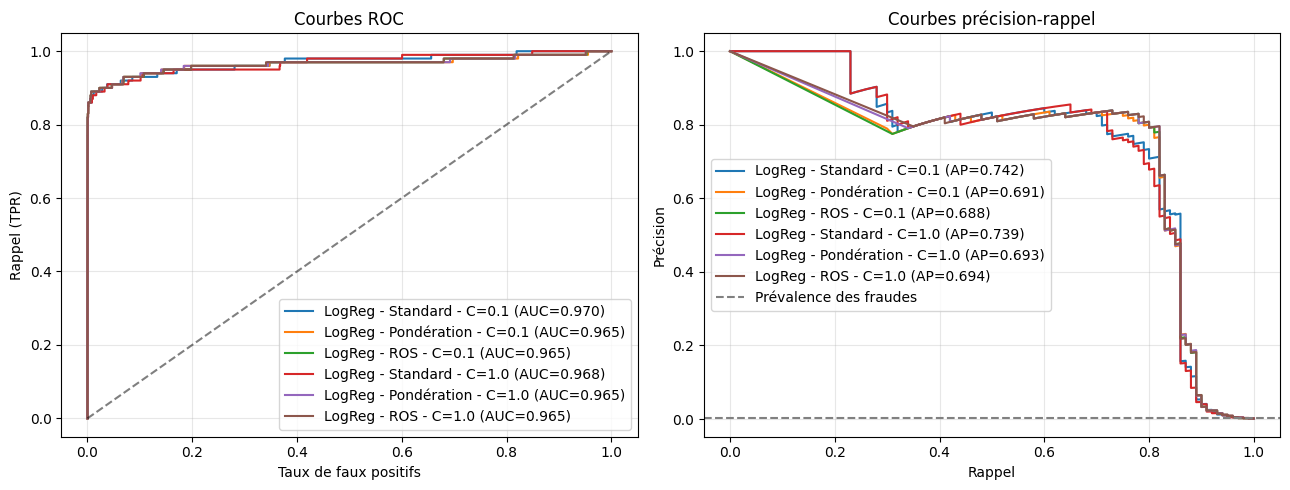

Arbre de décision


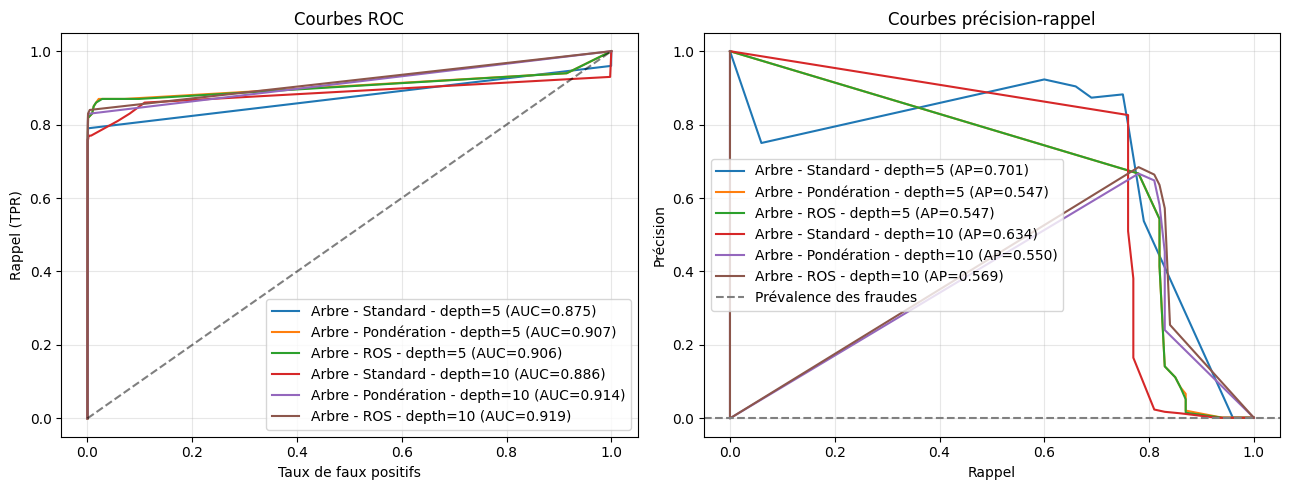

Détecteurs non supervisés


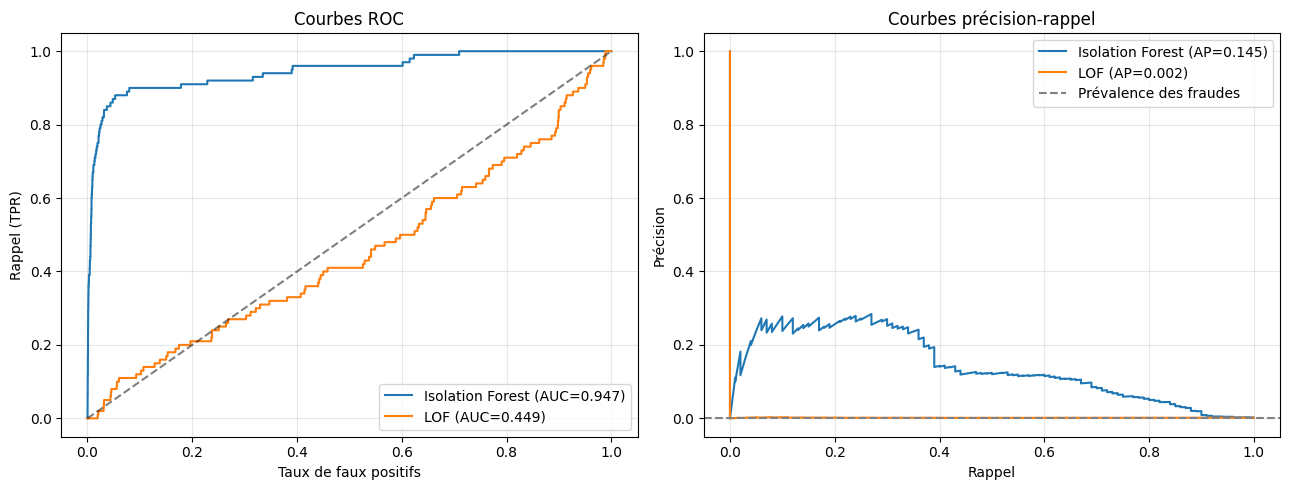

In [16]:

# Regroupement des scores par famille
scores_logreg_credit = {
    nom: scores
    for nom, scores in scores_tous_credit.items()
    if nom.startswith("LogReg")
}

scores_arbre_credit = {
    nom: scores
    for nom, scores in scores_tous_credit.items()
    if nom.startswith("Arbre")
}

scores_non_supervises_credit = {
    "Isolation Forest": scores_if_credit,
    "LOF": scores_lof_credit
}

# Courbes ROC et précision-rappel
print("Régression logistique")
utils.plot_roc_pr_curves(
    y_val_credit,
    scores_logreg_credit
)

print("Arbre de décision")
utils.plot_roc_pr_curves(
    y_val_credit,
    scores_arbre_credit
)

print("Détecteurs non supervisés")
utils.plot_roc_pr_curves(
    y_val_credit,
    scores_non_supervises_credit
)


**Observation:** The curves support the AP comparison: Logistic Regression provides the strongest overall fraud ranking in this experiment, while the unsupervised methods perform less well on the precision–recall trade-off.

An apparently high ROC-AUC does not guarantee a useful number of true-positive fraud alerts when fraudulent transactions are rare.

### 5.3 How the Decision Threshold Changes Metrics

We examine the impact of the decision threshold on **F1-score** and **balanced accuracy**. F1 balances precision and recall for fraud alerts; balanced accuracy averages fraud sensitivity and normal-transaction specificity.

The threshold that maximizes either metric may differ from the threshold required by the operational constraint.

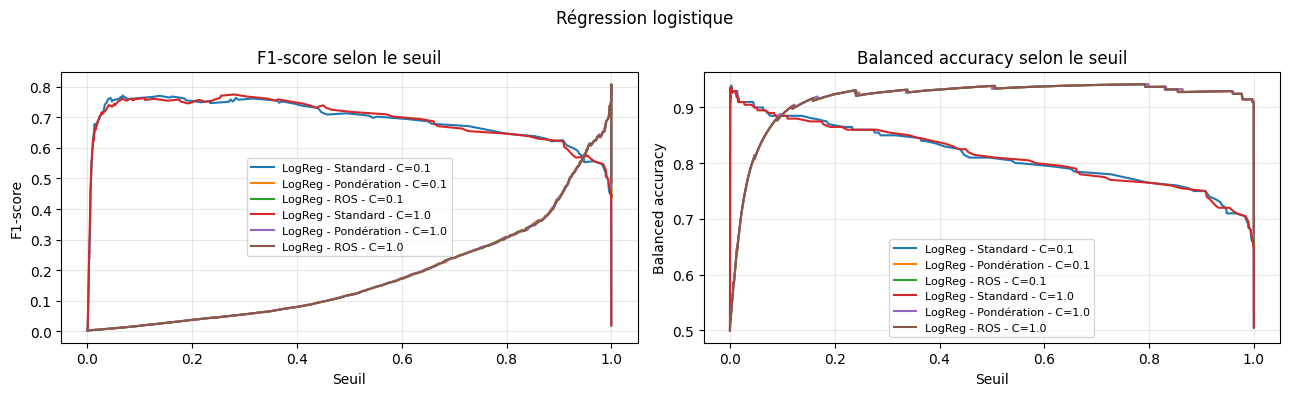

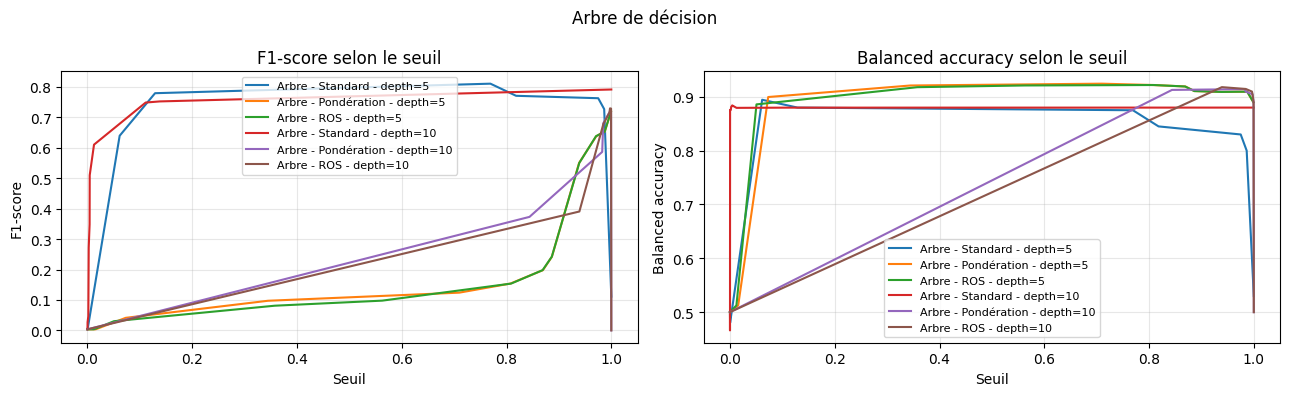

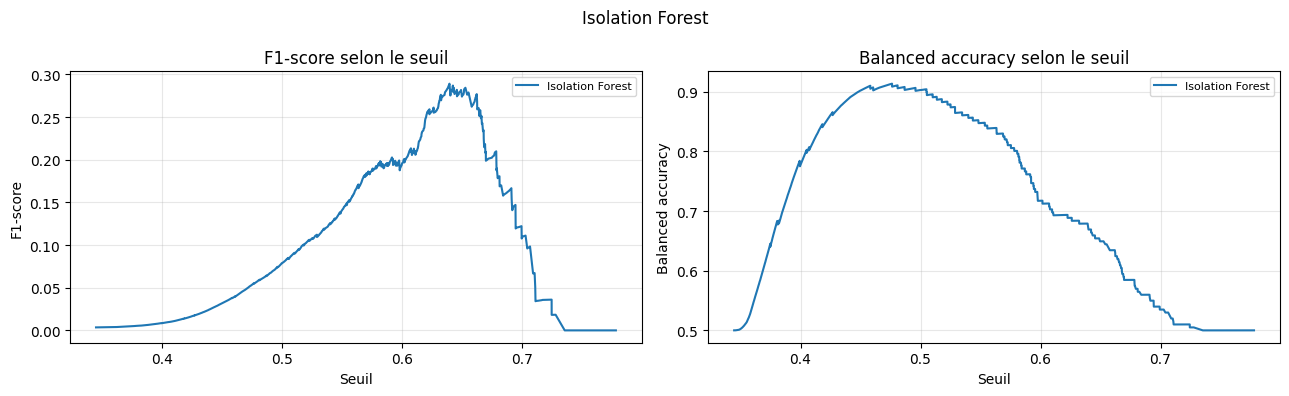

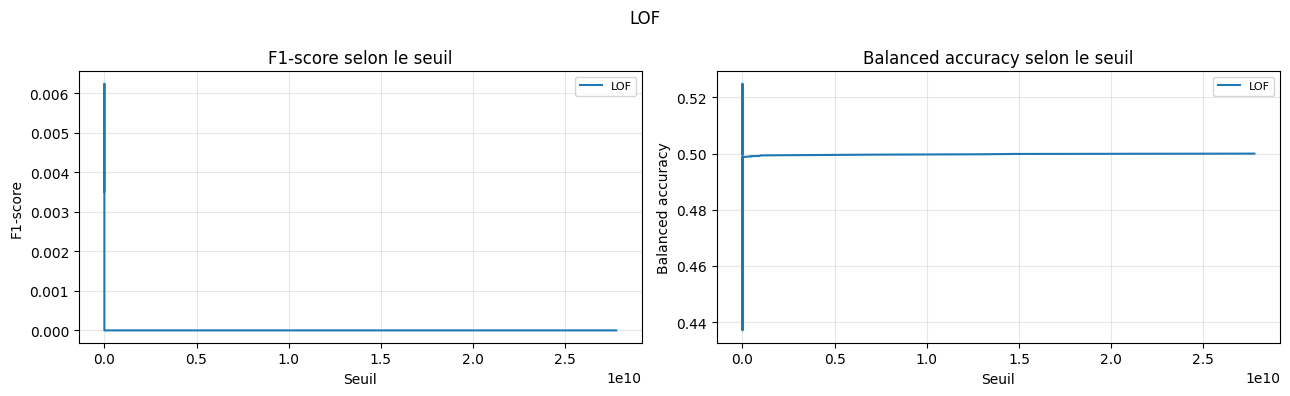

In [17]:

# Régression logistique : 6 configurations
utils.plot_metrics_threshold(
    y_val_credit,
    scores_logreg_credit,
    title="Régression logistique"
)

# Arbre de décision : 6 configurations
utils.plot_metrics_threshold(
    y_val_credit,
    scores_arbre_credit,
    title="Arbre de décision"
)

# Isolation Forest
utils.plot_metrics_threshold(
    y_val_credit,
    {"Isolation Forest": scores_if_credit},
    title="Isolation Forest"
)

# LOF
utils.plot_metrics_threshold(
    y_val_credit,
    {"LOF": scores_lof_credit},
    title="LOF"
)


**Observation:** The best F1 and balanced-accuracy thresholds vary across models and need not coincide. For deployment-style alert decisions, we therefore use a separately stated constraint: **maximize recall while maintaining at least 80% precision on Validation**.

## 6. Operating Threshold and Model Selection

### 6.1 Validation Threshold Search

For each configuration, we search on **Validation only** for a threshold that maximizes fraud recall with **precision ≥ 80%**. Configurations that do not meet the constraint are marked **not admissible**; their best-F1 thresholds are retained **for exploratory comparison only**.

The full-precision numerical threshold is preserved for predictions. Test is excluded from this search.

In [18]:

resultats_seuils_credit = []
seuils_optimaux_credit = {}

for nom, scores in scores_tous_credit.items():

    scores = np.asarray(scores)

    # Recherche du seuil sous contrainte
    resultat = utils.select_threshold(
        y_val_credit,
        scores,
        min_precision=0.80
    )

    if resultat is not None:
        seuil = resultat["Seuil"]
        statut = "Admissible"

    else:
        # Meilleur seuil F1 si aucun seuil admissible
        precision_c, rappel_c, seuils_c = precision_recall_curve(
            y_val_credit, scores
        )

        f1_c = (
            2 * precision_c[:-1] * rappel_c[:-1]
            / (precision_c[:-1] + rappel_c[:-1] + 1e-12)
        )

        seuil = seuils_c[np.argmax(f1_c)]
        statut = "Non admissible"

    y_pred = (scores >= seuil).astype(int)

    precision = precision_score(
        y_val_credit, y_pred, zero_division=0
    )
    rappel = recall_score(
        y_val_credit, y_pred, zero_division=0
    )

    seuils_optimaux_credit[nom] = (
        seuil if statut == "Admissible" else None
    )

    resultats_seuils_credit.append({
        "Modèle": nom,
        "Statut": statut,
        "Seuil": seuil,
        "Précision": precision,
        "Rappel": rappel,
        "Alertes": int(y_pred.sum())
    })

df_seuils_credit = pd.DataFrame(resultats_seuils_credit)

df_seuils_credit = df_seuils_credit.sort_values(
    ["Statut", "Rappel"],
    ascending=[True, False]
).reset_index(drop=True)

# Affichage sans arrondir les seuils
display(
    df_seuils_credit.style.format({
        "Seuil": "{:.12f}",
        "Précision": "{:.4f}",
        "Rappel": "{:.4f}"
    })
)


,Modèle,Statut,Seuil,Précision,Rappel,Alertes
0,LogReg - Pondération - C=0.1,Admissible,0.999982076480,0.8000,0.8000,100
1,LogReg - ROS - C=0.1,Admissible,0.999988015699,0.8081,0.8000,99
2,LogReg - Pondération - C=1.0,Admissible,0.999990410448,0.8081,0.8000,99
3,LogReg - ROS - C=1.0,Admissible,0.999991527267,0.8081,0.8000,99
4,Arbre - Standard - depth=5,Admissible,0.129032258065,0.8000,0.7600,95
5,Arbre - Standard - depth=10,Admissible,1.000000000000,0.8261,0.7600,92
6,LogReg - Standard - C=0.1,Admissible,0.273487264350,0.8000,0.7200,90
7,LogReg - Standard - C=1.0,Admissible,0.280355065035,0.8372,0.7200,86
8,Arbre - Pondération - depth=10,Non admissible,0.997541669649,0.6480,0.8100,125
9,Arbre - ROS - depth=10,Non admissible,0.997512801756,0.6639,0.8100,122


### 6.2 Default Thresholds vs Validation-Selected Thresholds

We compare default decisions (`0.5` for supervised probabilities and the estimator's internal offset for unsupervised scores) against validation-selected thresholds. For each case, we report precision, recall, F1, and alert volume.

A threshold marked **not admissible** is an exploratory F1 compromise, not a solution to the 80% precision requirement.

In [19]:

# Seuils par défaut
seuils_defaut_credit = {
    nom: 0.5
    for nom in scores_validation_credit
}

seuils_defaut_credit["Isolation Forest"] = -iforest_credit.offset_
seuils_defaut_credit["LOF"] = -lof_credit.offset_

# Seuils calculés sur Validation, y compris les non admissibles
seuils_calcules_credit = df_seuils_credit.set_index("Modèle")["Seuil"].to_dict()
statuts_credit = df_seuils_credit.set_index("Modèle")["Statut"].to_dict()

# Comparaison
comparaison_seuils_credit = []

for nom, scores in scores_tous_credit.items():

    for type_seuil, seuil in [
        ("Défaut", seuils_defaut_credit[nom]),
        ("Optimisé", seuils_calcules_credit[nom])
    ]:
        y_pred = (np.asarray(scores) >= seuil).astype(int)

        evaluation = utils.evaluate_anomalies(
            y_val_credit, y_pred
        )

        comparaison_seuils_credit.append({
            "Modèle": nom,
            "Type": type_seuil,
            "Statut": (
                statuts_credit[nom]
                if type_seuil == "Optimisé"
                else "Défaut"
            ),
            "Seuil": seuil,
            "Précision": precision_score(
                y_val_credit, y_pred, zero_division=0
            ),
            "Rappel": recall_score(
                y_val_credit, y_pred, zero_division=0
            ),
            "F1": evaluation["F1"],
            "Alertes": int(y_pred.sum())
        })

df_comparaison_credit = pd.DataFrame(comparaison_seuils_credit)

display(
    df_comparaison_credit.style.format({
        "Seuil": "{:.12f}",
        "Précision": "{:.4f}",
        "Rappel": "{:.4f}",
        "F1": "{:.4f}"
    })
)


,Modèle,Type,Statut,Seuil,Précision,Rappel,F1,Alertes
0,LogReg - Standard - C=0.1,Défaut,Défaut,0.500000000000,0.8356,0.6100,0.7052,73
1,LogReg - Standard - C=0.1,Optimisé,Admissible,0.273487264350,0.8000,0.7200,0.7579,90
2,LogReg - Pondération - C=0.1,Défaut,Défaut,0.500000000000,0.0637,0.8900,0.1188,1398
3,LogReg - Pondération - C=0.1,Optimisé,Admissible,0.999982076480,0.8000,0.8000,0.8000,100
4,LogReg - ROS - C=0.1,Défaut,Défaut,0.500000000000,0.0636,0.9000,0.1189,1414
5,LogReg - ROS - C=0.1,Optimisé,Admissible,0.999988015699,0.8081,0.8000,0.8040,99
6,LogReg - Standard - C=1.0,Défaut,Défaut,0.500000000000,0.8493,0.6200,0.7168,73
7,LogReg - Standard - C=1.0,Optimisé,Admissible,0.280355065035,0.8372,0.7200,0.7742,86
8,LogReg - Pondération - C=1.0,Défaut,Défaut,0.500000000000,0.0639,0.9000,0.1193,1409
9,LogReg - Pondération - C=1.0,Optimisé,Admissible,0.999990410448,0.8081,0.8000,0.8040,99


**Observation:** The threshold substantially changes the trade-off between missed frauds and false alerts. Admissible thresholds satisfy the precision requirement **on Validation** and optimize recall there; the same precision level is **not guaranteed** on the unseen Test partition.

Threshold values are kept unrounded in all prediction calculations.

### 6.3 Selecting the Final Supervised Model

From the admissible configurations, we select a single model using:

1. Precision ≥ 80% on Validation.
2. Highest recall among admissible candidates.
3. Highest precision as the first tie-breaker.
4. Highest AP as the second tie-breaker.

The selected **model and threshold are frozen** before the first final Test evaluation.

In [20]:
# Modèles respectant la contrainte de précision
modeles_admissibles_credit = df_seuils_credit[
    df_seuils_credit["Statut"] == "Admissible"
].copy()

# Ajouter l'AP de Validation
modeles_admissibles_credit = modeles_admissibles_credit.merge(
    df_scores_credit[["Modèle", "AP"]],
    on="Modèle",
    how="left"
)

# Classement par rappel, puis précision, puis AP
modeles_admissibles_credit = modeles_admissibles_credit.sort_values(
    ["Rappel", "Précision", "AP"],
    ascending=[False, False, False]
).reset_index(drop=True)

# Tableau des modèles admissibles
display(
    modeles_admissibles_credit.style.format({
        "Seuil": "{:.12f}",
        "Précision": "{:.4f}",
        "Rappel": "{:.4f}",
        "AP": "{:.4f}"
    })
)

# Vérifier qu'au moins un modèle est admissible
if modeles_admissibles_credit.empty:
    raise ValueError("Aucun modèle ne respecte la contrainte de précision.")

# Sélection finale
nom_retenu_credit = modeles_admissibles_credit.iloc[0]["Modèle"]

seuil_retenu_credit = seuils_optimaux_credit[nom_retenu_credit]

modele_retenu_credit = modeles_credit[nom_retenu_credit]

# Affichage
print("\nModèle retenu :", nom_retenu_credit)
print(f"Seuil retenu : {seuil_retenu_credit:.12f}")

,Modèle,Statut,Seuil,Précision,Rappel,Alertes,AP
0,LogReg - ROS - C=1.0,Admissible,0.999991527267,0.8081,0.8000,99,0.6942
1,LogReg - Pondération - C=1.0,Admissible,0.999990410448,0.8081,0.8000,99,0.6927
2,LogReg - ROS - C=0.1,Admissible,0.999988015699,0.8081,0.8000,99,0.6877
3,LogReg - Pondération - C=0.1,Admissible,0.999982076480,0.8000,0.8000,100,0.6915
4,Arbre - Standard - depth=10,Admissible,1.000000000000,0.8261,0.7600,92,0.6336
5,Arbre - Standard - depth=5,Admissible,0.129032258065,0.8000,0.7600,95,0.7013
6,LogReg - Standard - C=1.0,Admissible,0.280355065035,0.8372,0.7200,86,0.7392
7,LogReg - Standard - C=0.1,Admissible,0.273487264350,0.8000,0.7200,90,0.7417



Modèle retenu : LogReg - ROS - C=1.0
Seuil retenu : 0.999991527267


**Selected model (validation):** Logistic Regression with **RandomOverSampler**, `C=1.0`, and threshold **`0.999991527267`**.

This operating point was selected for **recall subject to precision ≥ 80%**, rather than for maximum AP. The threshold is retained at full floating-point precision in calculations and is not retuned on Test.

## 7. Held-Out Test Evaluation — Selected Supervised Model

We score the frozen Logistic Regression + ROS model on the untouched Test partition, apply the threshold selected on Validation, and report:

- AP and ROC-AUC on continuous scores.
- Precision, recall, F1, balanced accuracy, and the confusion matrix.
- Number of alerts, missed frauds, and false alerts.
- Training and scoring times.

This section represents the **final evaluation of the selected supervised model**; the later ECOD experiments are explicitly exploratory.

In [21]:

# Scores sur Test
scores_test_credit, temps_score_test_credit = (
    utils.compute_supervised_scores(
        modele_retenu_credit,
        X_test_credit_scaled
    )
)

# Prédictions avec le seuil sélectionné sur Validation
y_pred_test_credit = (
    scores_test_credit >= seuil_retenu_credit
).astype(int)

# Évaluation des scores
ap_test_credit, auc_test_credit = utils.evaluate_scores(
    y_test_credit,
    scores_test_credit
)

# Matrice de confusion et F1
evaluation_test_credit = utils.evaluate_anomalies(
    y_test_credit,
    y_pred_test_credit
)

# Autres métriques
precision_test_credit = precision_score(
    y_test_credit,
    y_pred_test_credit,
    zero_division=0
)

recall_test_credit = recall_score(
    y_test_credit,
    y_pred_test_credit,
    zero_division=0
)

balanced_acc_test_credit = balanced_accuracy_score(
    y_test_credit,
    y_pred_test_credit
)

# Tableau final
df_final_credit = pd.DataFrame([{
    "Méthode": nom_retenu_credit,
    "Prétraitement": "StandardScaler",
    "Déséquilibre": "RandomOverSampler",
    "AP": ap_test_credit,
    "ROC-AUC": auc_test_credit,
    "Seuil": seuil_retenu_credit,
    "Précision": precision_test_credit,
    "Rappel": recall_test_credit,
    "F1": evaluation_test_credit["F1"],
    "Balanced accuracy": balanced_acc_test_credit,
    "Alertes": int(y_pred_test_credit.sum()),
    "FP": evaluation_test_credit["FP"],
    "FN": evaluation_test_credit["FN"],
    "TP": evaluation_test_credit["TP"],
    "Temps fit (s)": df_resultats_credit.set_index("Modèle").loc[
        nom_retenu_credit, "Temps fit (s)"
    ],
    "Temps score (s)": temps_score_test_credit
}])

# Affichage du tableau
display(
    df_final_credit.style.format({
        "AP": "{:.4f}",
        "ROC-AUC": "{:.4f}",
        "Seuil": "{:.12f}",
        "Précision": "{:.4f}",
        "Rappel": "{:.4f}",
        "F1": "{:.4f}",
        "Balanced accuracy": "{:.4f}",
        "Temps fit (s)": "{:.4f}",
        "Temps score (s)": "{:.4f}"
    })
)

# Matrice de confusion
print("\nMatrice de confusion :")
print(evaluation_test_credit["Matrice"])

print("\nNombre total d'alertes :", int(y_pred_test_credit.sum()))
print("Frauds detected:", evaluation_test_credit["TP"])
print("Missed frauds:", evaluation_test_credit["FN"])


,Méthode,Prétraitement,Déséquilibre,AP,ROC-AUC,Seuil,Précision,Rappel,F1,Balanced accuracy,Alertes,FP,FN,TP,Temps fit (s),Temps score (s)
0,LogReg - ROS - C=1.0,StandardScaler,RandomOverSampler,0.6805,0.9846,0.999991527267,0.7931,0.7263,0.7582,0.8630,87,18,26,69,1.3967,0.0113



Matrice de confusion :
[[56840    18]
 [   26    69]]

Nombre total d'alertes : 87
Frauds detected: 69
Missed frauds: 26


## 8. Test Results and Operational Interpretation

The selected model produces **87 alerts** among **56,953 test transactions**:

- **69 true positives (TP):** Fraudulent transactions correctly flagged.
- **18 false positives (FP):** Legitimate transactions flagged.
- **26 false negatives (FN):** Frauds not detected.

**Test precision = 79.31%**, **recall = 72.63%**, and **F1 = 0.7582**. The precision falls slightly below the **80% constraint achieved on Validation** (80.81%). This is not a modeling error: it illustrates that performance estimates vary across data partitions.

**Interpretation:** The model detects most frauds with a relatively small alert volume but still misses 26 frauds. A chronological holdout and additional real-world monitoring would be necessary before operational use. The validation-selected threshold is **not readjusted** to the test results.

## 9. Additional Unsupervised Experiment — ECOD

### 9.1 Why ECOD?

We add **Empirical Cumulative Distribution Functions for Outlier Detection (ECOD)** as an exploratory unsupervised baseline. ECOD estimates feature-wise empirical tail probabilities and combines them into continuous anomaly scores.

**Why this method?** It is computationally practical, requires few tuning parameters, and avoids distance-based neighborhood search in high dimensions. Alternatives considered included One-Class SVM, DBSCAN, and K-Means-based anomaly heuristics.

**Main limitation:** Feature-wise tail rarity can miss fraud patterns that are unusual **only through interactions among features**.

**Reference:** Li et al. (2022), *ECOD: Unsupervised Outlier Detection Using Empirical Cumulative Distribution Functions*.

**Documentation:** https://pyod.readthedocs.io/en/latest/pyod.models.tabular.html

> **Scope:** This is an additional experiment reported after the main supervised model's final test evaluation, not a retrospective replacement of that frozen model.

### 9.2 How ECOD Produces Anomaly Scores

ECOD estimates empirical left- and right-tail probabilities for each feature, converts tail probabilities into rarity scores, and aggregates the contributions. **Higher ECOD score = more anomalous transaction**; the score is **not a calibrated probability of fraud**.

Because ECOD primarily works with rank/tail information, the experiment uses the original-scale features. Statistical rarity does not necessarily imply fraudulent activity.

### 9.3 ECOD Setup and Evaluation Protocol

We use `ECOD(contamination=0.1)`. This parameter sets the estimator's internal decision cutoff; the notebook instead uses **continuous scores** and tunes a separate operational threshold on Validation.

- Fit on the original-scale `X_train_credit` **without labels**.
- Score `X_val_credit` and evaluate using validation labels.
- Select a threshold **only on Validation**.
- Report an exploratory Test evaluation, keeping its threshold fixed.

ECOD's limited ability to model feature interactions is an important caveat.

### 9.4 Fitting ECOD and Computing Validation Scores

We train ECOD on Train, compute continuous anomaly scores on Validation, and record both fit and scoring time. No validation or test labels are used in fitting.

In [22]:

# Initialisation
ecod_credit = ECOD(contamination=0.1)

# Apprentissage sur Train
ecod_credit, temps_fit_ecod_credit = utils.fit_model(
    ecod_credit,
    X_train_credit
)

# Calcul des scores sur Validation
scores_val_ecod_credit, temps_score_ecod_credit = (
    utils.compute_anomaly_scores(
        ecod_credit,
        X_val_credit
    )
)

# Résultats
print(f"ECOD | Fit : {temps_fit_ecod_credit:.4f} s")
print(f"ECOD | Score : {temps_score_ecod_credit:.4f} s")

print(
    f"Scores min/max : "
    f"{np.min(scores_val_ecod_credit):.4f} / "
    f"{np.max(scores_val_ecod_credit):.4f}"
)

print("Nombre de scores :", len(scores_val_ecod_credit))


ECOD | Fit : 3.2572 s
ECOD | Score : 2.2413 s
Scores min/max : 29.2780 / 295.4322
Nombre de scores : 56825


### 9.5 Validation Ranking — AP and ROC-AUC

We assess continuous ECOD scores with AP and ROC-AUC, then visualize the ranking trade-off with precision–recall and ROC curves. **Neither ranking metric requires a binary decision threshold**.

ECOD | AP : 0.2178
ECOD | ROC-AUC : 0.9474


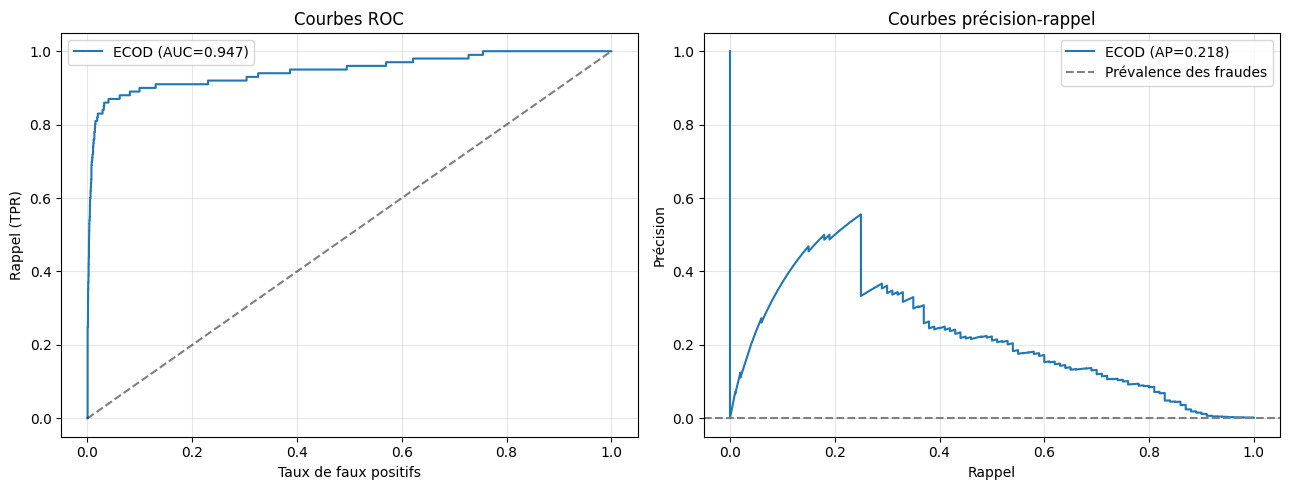

In [23]:
# Évaluation des scores sur Validation
ap_ecod_credit, auc_ecod_credit = utils.evaluate_scores(
    y_val_credit,
    scores_val_ecod_credit
)

# Résultats
print(f"ECOD | AP : {ap_ecod_credit:.4f}")
print(f"ECOD | ROC-AUC : {auc_ecod_credit:.4f}")

# Courbes ROC et précision-rappel
utils.plot_roc_pr_curves(
    y_val_credit,
    {"ECOD": scores_val_ecod_credit}
)

### 9.6 ECOD Threshold Under the 80% Precision Constraint

We search for the validation threshold that maximizes recall with precision ≥ 80%. If no eligible threshold exists, we report a **best-F1 exploratory threshold** and mark the operational objective as unmet. This exploratory threshold is not presented as satisfying the precision constraint.

In [24]:

# Recherche du seuil sous contrainte
resultat_seuil_ecod_credit = utils.select_threshold(
    y_val_credit,
    scores_val_ecod_credit,
    min_precision=0.80
)

if resultat_seuil_ecod_credit is not None:
    seuil_ecod_credit = resultat_seuil_ecod_credit["Seuil"]
    statut_ecod_credit = "Admissible"

else:
    # Meilleur compromis exploratoire selon le F1
    precision_c, rappel_c, seuils_c = precision_recall_curve(
        y_val_credit,
        scores_val_ecod_credit
    )

    p = precision_c[:-1]
    r = rappel_c[:-1]

    f1_c = np.divide(
        2 * p * r,
        p + r,
        out=np.zeros_like(p),
        where=(p + r) > 0
    )

    seuil_ecod_credit = seuils_c[np.argmax(f1_c)]
    statut_ecod_credit = "Non admissible"

# Prédictions sur Validation
y_pred_val_ecod_credit = (
    np.asarray(scores_val_ecod_credit) >= seuil_ecod_credit
).astype(int)

# Évaluation
evaluation_val_ecod_credit = utils.evaluate_anomalies(
    y_val_credit,
    y_pred_val_ecod_credit
)

print("Statut :", statut_ecod_credit)
print(f"Seuil : {seuil_ecod_credit:.12f}")

print(
    "Précision :",
    f"{precision_score(y_val_credit, y_pred_val_ecod_credit, zero_division=0):.4f}"
)

print(
    "Rappel :",
    f"{recall_score(y_val_credit, y_pred_val_ecod_credit, zero_division=0):.4f}"
)

print(f"F1 : {evaluation_val_ecod_credit['F1']:.4f}")
print("Alertes :", int(y_pred_val_ecod_credit.sum()))
print("FP :", evaluation_val_ecod_credit["FP"])
print("FN :", evaluation_val_ecod_credit["FN"])
print("TP :", evaluation_val_ecod_credit["TP"])


Statut : Non admissible
Seuil : 156.192644121043
Précision : 0.5556
Rappel : 0.2500
F1 : 0.3448
Alertes : 45
FP : 20
FN : 75
TP : 25


**Observation:** No ECOD threshold meets the minimum **80% validation precision** requirement while producing usable fraud alerts. The best-F1 exploratory threshold is approximately **156.192644121043**.

At this threshold, ECOD detects **25 of 100 validation frauds**, produces **20 false alerts**, and achieves **precision 55.56%, recall 25%, F1 ≈ 0.3448**. **The operational goal is not achieved.**

### 9.7 ECOD Score Distribution by Class

We display the validation score distributions for legitimate and fraudulent transactions, with the best-F1 exploratory threshold marked. A logarithmic count axis helps reveal both distributions despite substantial class imbalance.

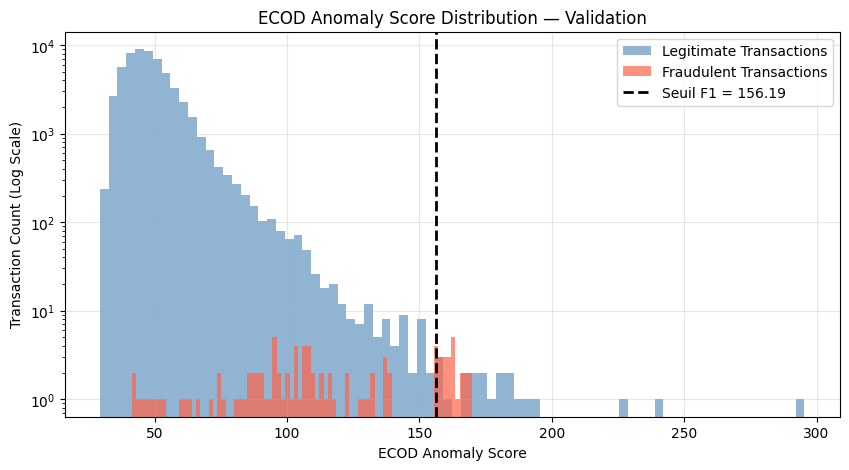

In [25]:

# Scores par classe
scores_normaux_ecod_credit = np.asarray(scores_val_ecod_credit)[
    np.asarray(y_val_credit) == 0
]

scores_fraudes_ecod_credit = np.asarray(scores_val_ecod_credit)[
    np.asarray(y_val_credit) == 1
]

# Distribution des scores
plt.figure(figsize=(10, 5))

plt.hist(
    scores_normaux_ecod_credit,
    bins=80,
    alpha=0.6,
    label="Legitimate Transactions",
    color="steelblue"
)

plt.hist(
    scores_fraudes_ecod_credit,
    bins=80,
    alpha=0.7,
    label="Fraudulent Transactions",
    color="tomato"
)

# Seuil sélectionné sur Validation
plt.axvline(
    seuil_ecod_credit,
    color="black",
    linestyle="--",
    linewidth=2,
    label=f"Seuil F1 = {seuil_ecod_credit:.2f}"
)

plt.yscale("log")
plt.xlabel("ECOD Anomaly Score")
plt.ylabel("Transaction Count (Log Scale)")
plt.title("ECOD Anomaly Score Distribution — Validation")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


**Observation:** The score distributions of legitimate transactions and frauds overlap. With the chosen F1-based threshold, ECOD finds 25 frauds but also flags 20 legitimate transactions, explaining why its precision remains below the operational requirement.

### 9.8 Precision and Recall Across ECOD Thresholds

We visualize how ECOD's validation precision and recall change with the decision threshold. The horizontal line marks **80% required precision** and the vertical line marks the **exploratory F1-maximizing threshold**.

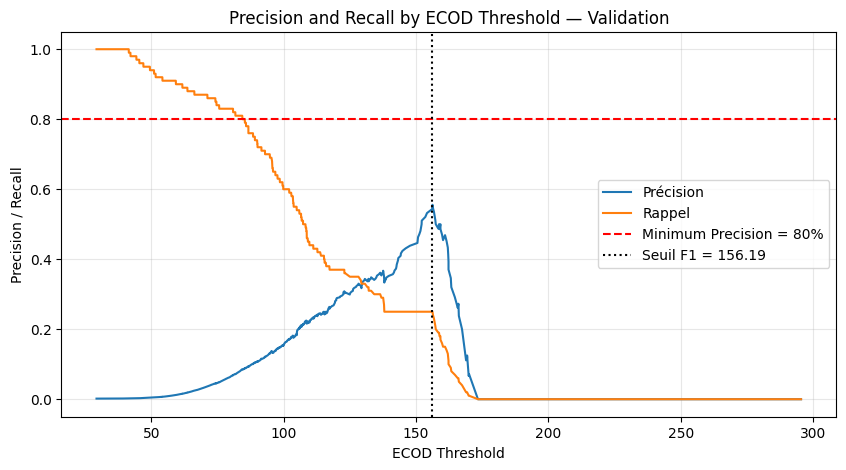

In [26]:

# Courbe précision-rappel en fonction des seuils
precision_ecod_credit, rappel_ecod_credit, seuils_ecod_credit = (
    precision_recall_curve(
        y_val_credit,
        scores_val_ecod_credit
    )
)

# Alignement avec les seuils
precision_ecod_credit = precision_ecod_credit[:-1]
rappel_ecod_credit = rappel_ecod_credit[:-1]

# Visualisation
plt.figure(figsize=(10, 5))

plt.plot(
    seuils_ecod_credit,
    precision_ecod_credit,
    label="Précision"
)

plt.plot(
    seuils_ecod_credit,
    rappel_ecod_credit,
    label="Rappel"
)

# Contrainte opérationnelle
plt.axhline(
    0.80,
    color="red",
    linestyle="--",
    label="Minimum Precision = 80%"
)

# Seuil sélectionné précédemment
plt.axvline(
    seuil_ecod_credit,
    color="black",
    linestyle=":",
    label=f"Seuil F1 = {seuil_ecod_credit:.2f}"
)

plt.xlabel("ECOD Threshold")
plt.ylabel("Precision / Recall")
plt.title("Precision and Recall by ECOD Threshold — Validation")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


**Observation:** Increasing the threshold generally decreases recall, while precision can vary non-monotonically. At the best-F1 threshold, the detector issues **45 alerts**: 25 true frauds and 20 false positives (precision **55.56%**, recall **25%**).

No threshold with at least one alert satisfies the 80% precision requirement on Validation. ECOD remains an **exploratory** alternative.

### 9.9 Exploratory ECOD Test Evaluation

We evaluate ECOD on the fixed Test partition using the threshold chosen on Validation. This threshold **maximizes F1 but does not meet the operational precision constraint**, so this is an additional exploratory result rather than a successful operational model. We report ranking, classification metrics, and runtime.

In [27]:

# Calcul des scores sur Test
scores_test_ecod_credit, temps_score_test_ecod_credit = (
    utils.compute_anomaly_scores(
        ecod_credit,
        X_test_credit
    )
)

# Prédictions avec le seuil figé sur Validation
y_pred_test_ecod_credit = (
    np.asarray(scores_test_ecod_credit) >= seuil_ecod_credit
).astype(int)

# Évaluation des scores
ap_test_ecod_credit, auc_test_ecod_credit = utils.evaluate_scores(
    y_test_credit,
    scores_test_ecod_credit
)

# Évaluation des prédictions
evaluation_test_ecod_credit = utils.evaluate_anomalies(
    y_test_credit,
    y_pred_test_ecod_credit
)

precision_test_ecod_credit = precision_score(
    y_test_credit,
    y_pred_test_ecod_credit,
    zero_division=0
)

rappel_test_ecod_credit = recall_score(
    y_test_credit,
    y_pred_test_ecod_credit,
    zero_division=0
)

balanced_acc_test_ecod_credit = balanced_accuracy_score(
    y_test_credit,
    y_pred_test_ecod_credit
)

# Tableau des résultats
df_test_ecod_credit = pd.DataFrame([{
    "Méthode": "ECOD",
    "AP": ap_test_ecod_credit,
    "ROC-AUC": auc_test_ecod_credit,
    "Seuil": seuil_ecod_credit,
    "Précision": precision_test_ecod_credit,
    "Rappel": rappel_test_ecod_credit,
    "F1": evaluation_test_ecod_credit["F1"],
    "Balanced accuracy": balanced_acc_test_ecod_credit,
    "Alertes": int(y_pred_test_ecod_credit.sum()),
    "FP": evaluation_test_ecod_credit["FP"],
    "FN": evaluation_test_ecod_credit["FN"],
    "TP": evaluation_test_ecod_credit["TP"],
    "Temps fit (s)": temps_fit_ecod_credit,
    "Temps score (s)": temps_score_test_ecod_credit,
    "Statut": statut_ecod_credit
}])

display(
    df_test_ecod_credit.style.format({
        "AP": "{:.4f}",
        "ROC-AUC": "{:.4f}",
        "Seuil": "{:.12f}",
        "Précision": "{:.4f}",
        "Rappel": "{:.4f}",
        "F1": "{:.4f}",
        "Balanced accuracy": "{:.4f}",
        "Temps fit (s)": "{:.4f}",
        "Temps score (s)": "{:.4f}"
    })
)

# Matrice de confusion
print("\nMatrice de confusion :")
print(evaluation_test_ecod_credit["Matrice"])


,Méthode,AP,ROC-AUC,Seuil,Précision,Rappel,F1,Balanced accuracy,Alertes,FP,FN,TP,Temps fit (s),Temps score (s),Statut
0,ECOD,0.1577,0.9386,156.192644121043,0.4118,0.1474,0.2171,0.5735,34,20,81,14,3.2572,2.3653,Non admissible



Matrice de confusion :
[[56838    20]
 [   81    14]]


**Observation:** On Test, ECOD issues **34 alerts**, with **14 detected frauds**, **20 false positives**, and **81 missed frauds** (out of 95 frauds).

Its precision is **41.18%**, recall **14.74%**, and F1 **0.2171**. AP decreases from **0.2178** on Validation to **0.1577** on Test. The frozen validation threshold is **not modified**.

**Conclusion:** Despite a relatively high ROC-AUC (0.9386), ECOD has insufficient alert precision and recall for the stated operational objective.

### 9.10 ECOD vs Isolation Forest and LOF

We compare three unsupervised methods on the **same Validation partition** using AP, ROC-AUC, precision, recall, F1, balanced accuracy, alert counts, and runtime.

Each method uses its validation-selected precision-constrained threshold, or an explicitly **exploratory best-F1 threshold** when the constraint cannot be met. This comparison is not a new selection of the original supervised model.

In [28]:

# Méthodes non supervisées déjà entraînées
modeles_non_supervises_credit = [
    (
        "Isolation Forest",
        scores_if_credit,
        temps_fit_if_credit,
        temps_score_if_credit
    ),
    (
        "LOF",
        scores_lof_credit,
        temps_fit_lof_credit,
        temps_score_lof_credit
    ),
    (
        "ECOD",
        scores_val_ecod_credit,
        temps_fit_ecod_credit,
        temps_score_ecod_credit
    )
]

comparaison_non_supervisee_credit = []

for nom, scores, temps_fit, temps_score in modeles_non_supervises_credit:

    scores = np.asarray(scores)

    # Métriques de classement
    ap, auc = utils.evaluate_scores(y_val_credit, scores)

    # Recherche du seuil sous contrainte
    resultat = utils.select_threshold(
        y_val_credit,
        scores,
        min_precision=0.80
    )

    if resultat is not None:
        seuil = resultat["Seuil"]
        statut = "Admissible"

    else:
        # Seuil exploratoire maximisant le F1
        precision_c, rappel_c, seuils_c = precision_recall_curve(
            y_val_credit,
            scores
        )

        p = precision_c[:-1]
        r = rappel_c[:-1]

        f1_c = np.divide(
            2 * p * r,
            p + r,
            out=np.zeros_like(p),
            where=(p + r) > 0
        )

        seuil = seuils_c[np.argmax(f1_c)]
        statut = "Non admissible"

    # Prédictions
    y_pred = (scores >= seuil).astype(int)

    # Évaluation
    evaluation = utils.evaluate_anomalies(
        y_val_credit,
        y_pred
    )

    comparaison_non_supervisee_credit.append({
        "Méthode": nom,
        "AP": ap,
        "ROC-AUC": auc,
        "Seuil": seuil,
        "Précision": precision_score(
            y_val_credit, y_pred, zero_division=0
        ),
        "Rappel": recall_score(
            y_val_credit, y_pred, zero_division=0
        ),
        "F1": evaluation["F1"],
        "Balanced accuracy": balanced_accuracy_score(
            y_val_credit, y_pred
        ),
        "Alertes": int(y_pred.sum()),
        "FP": evaluation["FP"],
        "FN": evaluation["FN"],
        "TP": evaluation["TP"],
        "Temps fit (s)": temps_fit,
        "Temps score (s)": temps_score,
        "Statut": statut
    })

# Tableau comparatif
df_comparaison_non_supervisee_credit = pd.DataFrame(
    comparaison_non_supervisee_credit
)

display(
    df_comparaison_non_supervisee_credit.style.format({
        "AP": "{:.4f}",
        "ROC-AUC": "{:.4f}",
        "Seuil": "{:.12f}",
        "Précision": "{:.4f}",
        "Rappel": "{:.4f}",
        "F1": "{:.4f}",
        "Balanced accuracy": "{:.4f}",
        "Temps fit (s)": "{:.4f}",
        "Temps score (s)": "{:.4f}"
    })
)


,Méthode,AP,ROC-AUC,Seuil,Précision,Rappel,F1,Balanced accuracy,Alertes,FP,FN,TP,Temps fit (s),Temps score (s),Statut
0,Isolation Forest,0.1445,0.9469,0.639208235917,0.2416,0.3600,0.2892,0.6790,149,113,64,36,0.4474,0.3758,Non admissible
1,LOF,0.0017,0.4494,1.589263287230,0.0032,0.1100,0.0062,0.5249,3426,3415,89,11,73.0333,22.7931,Non admissible
2,ECOD,0.2178,0.9474,156.192644121043,0.5556,0.2500,0.3448,0.6248,45,20,75,25,3.2572,2.2413,Non admissible


**Validation comparison:** Among these three unsupervised approaches, ECOD has the strongest AP (**0.2178**) and F1 (**0.3448**) under the reported decision rules. It detects 25 frauds with 20 false alerts; Isolation Forest detects 36 with 113 false alerts, and LOF has F1 ≈ 0.0062.

**Runtime:** Isolation Forest is fastest in the recorded run, ECOD follows, and LOF is most computationally expensive.

**Limitations:** None meets precision ≥ 80% on Validation. ECOD's performance also drops on the held-out Test set. Thus ECOD is the strongest of these **unsupervised exploratory baselines**, not an operationally admissible fraud detector.

## 10. Explaining Isolation Forest Alerts with SHAP

This section explains **Isolation Forest anomaly scores**, not the predictions of the selected supervised Logistic Regression model. We reuse the previously fitted Isolation Forest and its **validation-selected exploratory F1 threshold**, without re-fitting the model or tuning on Test.

We inspect **six test transactions**: two true positives (TP), two false positives (FP), and two false negatives (FN), where available. SHAP compares each score against a **50-observation reference sampled from Train only**.

**Important:** SHAP attributes contributions to a model score, not causal importance for real-world fraud.

In [29]:

# Modèle Isolation Forest déjà entraîné en partie 2
modele_if_shap_credit = iforest_credit

# Résultat du choix de seuil en partie 2
resultat_seuil_if_credit = seuils_calcules_credit["Isolation Forest"]

# Vérification des informations disponibles
print("Modèle :", type(modele_if_shap_credit).__name__)
print("Résultat du seuil :", resultat_seuil_if_credit)
print("Train :", X_train_credit.shape)
print("Validation :", X_val_credit.shape)
print("Test :", X_test_credit.shape)


Modèle : IsolationForest
Résultat du seuil : 0.63920823591712
Train : (171029, 29)
Validation : (56825, 29)
Test : (56953, 29)


### 10.1 Selecting Test Transactions to Explain

We apply the existing Isolation Forest threshold to Test and distinguish:

- **TP:** Actual fraud correctly flagged.
- **FP:** Legitimate transaction incorrectly flagged.
- **FN:** Actual fraud missed.

We sample up to two examples per category with a fixed seed. If a category has fewer than two examples, additional test observations fill the six-case illustration.

In [30]:

# Récupération du seuil déjà calculé
seuil_if_shap_credit = float(resultat_seuil_if_credit)

# Calcul des scores sur Test avec le modèle déjà entraîné
scores_test_if_shap_credit, temps_score_if_shap_credit = (
    utils.compute_anomaly_scores(
        modele_if_shap_credit,
        X_test_credit
    )
)

# Prédictions avec le seuil de la partie 2
pred_test_if_shap_credit = (
    scores_test_if_shap_credit >= seuil_if_shap_credit
).astype(int)

y_test_array_credit = np.asarray(y_test_credit)

# Identifier les catégories
indices_tp_credit = np.where(
    (y_test_array_credit == 1) & (pred_test_if_shap_credit == 1)
)[0]

indices_fp_credit = np.where(
    (y_test_array_credit == 0) & (pred_test_if_shap_credit == 1)
)[0]

indices_fn_credit = np.where(
    (y_test_array_credit == 1) & (pred_test_if_shap_credit == 0)
)[0]

print("TP disponibles :", len(indices_tp_credit))
print("FP disponibles :", len(indices_fp_credit))
print("FN disponibles :", len(indices_fn_credit))

# Sélection reproductible des observations
rng_shap_credit = np.random.default_rng(SEED)

categories_disponibles = {
    "TP": indices_tp_credit,
    "FP": indices_fp_credit,
    "FN": indices_fn_credit
}

selection_shap_credit = {}

# Sélectionner jusqu'à deux observations par catégorie
for categorie, indices in categories_disponibles.items():
    n = min(2, len(indices))

    selection_shap_credit[categorie] = rng_shap_credit.choice(
        indices, size=n, replace=False
    )

    if n < 2:
        print(f"{categorie} : seulement {n} observation(s) disponible(s)")

# Compléter jusqu'à six observations, si nécessaire
indices_selection_shap_credit = np.concatenate(
    list(selection_shap_credit.values())
)

manquantes = 6 - len(indices_selection_shap_credit)

if manquantes > 0:
    indices_restants = np.setdiff1d(
        np.arange(len(y_test_array_credit)),
        indices_selection_shap_credit
    )

    supplement = rng_shap_credit.choice(
        indices_restants,
        size=manquantes,
        replace=False
    )

    indices_selection_shap_credit = np.concatenate([
        indices_selection_shap_credit,
        supplement
    ])

# Catégories réelles des six observations
categories_selection_shap_credit = np.select(
    [
        (y_test_array_credit[indices_selection_shap_credit] == 1)
        & (pred_test_if_shap_credit[indices_selection_shap_credit] == 1),

        (y_test_array_credit[indices_selection_shap_credit] == 0)
        & (pred_test_if_shap_credit[indices_selection_shap_credit] == 1),

        (y_test_array_credit[indices_selection_shap_credit] == 1)
        & (pred_test_if_shap_credit[indices_selection_shap_credit] == 0)
    ],
    ["TP", "FP", "FN"],
    default="TN"
)

# Six transactions à expliquer
X_shap_credit = X_test_credit.iloc[
    indices_selection_shap_credit
].copy()

# Tableau récapitulatif
df_selection_shap_credit = pd.DataFrame({
    "Catégorie": categories_selection_shap_credit,    
    "Indice original": X_shap_credit.index,
    "Classe réelle": y_test_array_credit[indices_selection_shap_credit],
    "Classe prédite": pred_test_if_shap_credit[indices_selection_shap_credit],
    "Score IF": scores_test_if_shap_credit[indices_selection_shap_credit]
})

print(f"\nSeuil IF : {seuil_if_shap_credit:.12f}")
print(f"Temps de calcul des scores : {temps_score_if_shap_credit:.4f} s")

display(df_selection_shap_credit.round(6))


TP disponibles : 17
FP disponibles : 102
FN disponibles : 78

Seuil IF : 0.639208235917
Temps de calcul des scores : 0.3473 s


,Catégorie,Indice original,Classe réelle,Classe prédite,Score IF
0,TP,10630,1,1,0.704270
1,TP,150680,1,1,0.695549
2,FP,125478,0,1,0.642623
3,FP,284281,0,1,0.655429
4,FN,203700,1,0,0.540093
5,FN,6899,1,0,0.615899


### 10.2 SHAP Background Reference

We randomly sample **50 training observations** to define the SHAP reference distribution. The same original-scale features are used as for Isolation Forest fitting. No test transaction is included in this background reference.

In [31]:

# Référence SHAP issue uniquement de Train
X_background_shap_credit = X_train_credit.sample(
    n=50,
    random_state=SEED
).copy()

# Vérification des dimensions et des variables
print("Référence SHAP :", X_background_shap_credit.shape)
print("Transactions à expliquer :", X_shap_credit.shape)

print(
    "Colonnes identiques :",
    X_background_shap_credit.columns.equals(X_shap_credit.columns)
)

print(
    "Chevauchement avec Test :",
    X_background_shap_credit.index.isin(X_test_credit.index).sum()
)


Référence SHAP : (50, 29)
Transactions à expliquer : (6, 29)
Colonnes identiques : True
Chevauchement avec Test : 0


### 10.3 Permutation SHAP on Anomaly Scores

We apply a permutation-based SHAP explainer to `-score_samples()`, preserving the convention **higher score = more anomalous**.

- **Positive contribution:** Raises the anomaly score relative to the background.
- **Negative contribution:** Lowers the anomaly score relative to the background.

We verify that the baseline plus feature contributions reconstructs the model score for the six explained transactions. Explanation values are model-relative and **not causal evidence** of fraud.

In [32]:

# Fonction de score expliquée par SHAP
def score_anomalie_shap_credit(X):
    X_df = pd.DataFrame(
        X,
        columns=X_train_credit.columns
    )
    return -modele_if_shap_credit.score_samples(X_df)


# Référence SHAP
masker_shap_credit = shap.maskers.Independent(
    X_background_shap_credit,
    max_samples=50
)

# Explainer par permutations
explainer_shap_credit = shap.Explainer(
    score_anomalie_shap_credit,
    masker_shap_credit,
    algorithm="permutation",
    seed=SEED
)

# Contributions des six transactions
shap_values_credit = explainer_shap_credit(
    X_shap_credit,
    max_evals=10 * (2 * X_shap_credit.shape[1] + 1)
)

# Reconstruction des scores
scores_reconstruits_credit = (
    shap_values_credit.base_values
    + shap_values_credit.values.sum(axis=1)
)

scores_originaux_credit = df_selection_shap_credit["Score IF"].to_numpy()

print("Dimensions SHAP :", shap_values_credit.values.shape)

print(
    "Scores IF :",
    np.round(scores_originaux_credit, 6)
)

print(
    "Scores reconstruits :",
    np.round(scores_reconstruits_credit, 6)
)

print(
    "Reconstruction correcte :",
    np.allclose(
        scores_originaux_credit,
        scores_reconstruits_credit,
        atol=1e-6
    )
)


Dimensions SHAP : (6, 29)
Scores IF : [0.70427  0.695549 0.642623 0.655429 0.540093 0.615899]
Scores reconstruits : [0.70427  0.695549 0.642623 0.655429 0.540093 0.615899]
Reconstruction correcte : True


### 10.4 SHAP Waterfall Explanations

Waterfall plots show how individual features move each transaction's anomaly score away from the background reference. We compare correctly detected frauds (TP), false alerts (FP), and missed frauds (FN).


TP — Transaction 10630
Score IF : 0.704270
Seuil IF : 0.639208

TP — Transaction 150680
Score IF : 0.695549
Seuil IF : 0.639208

FP — Transaction 125478
Score IF : 0.642623
Seuil IF : 0.639208

FP — Transaction 284281
Score IF : 0.655429
Seuil IF : 0.639208

FN — Transaction 203700
Score IF : 0.540093
Seuil IF : 0.639208

FN — Transaction 6899
Score IF : 0.615899
Seuil IF : 0.639208

TP — Transaction 10630
Anomaly score: 0.704270
Decision threshold: 0.639208


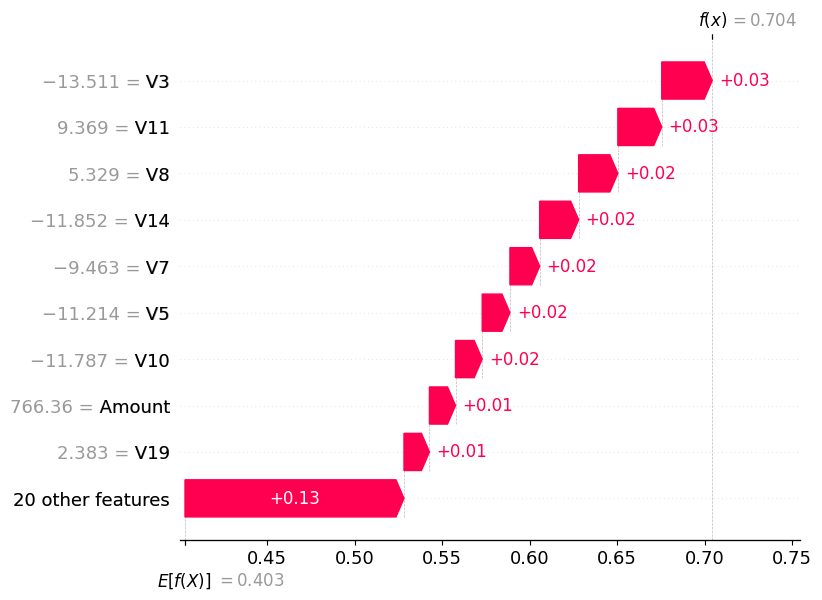


TP — Transaction 150680
Anomaly score: 0.695549
Decision threshold: 0.639208


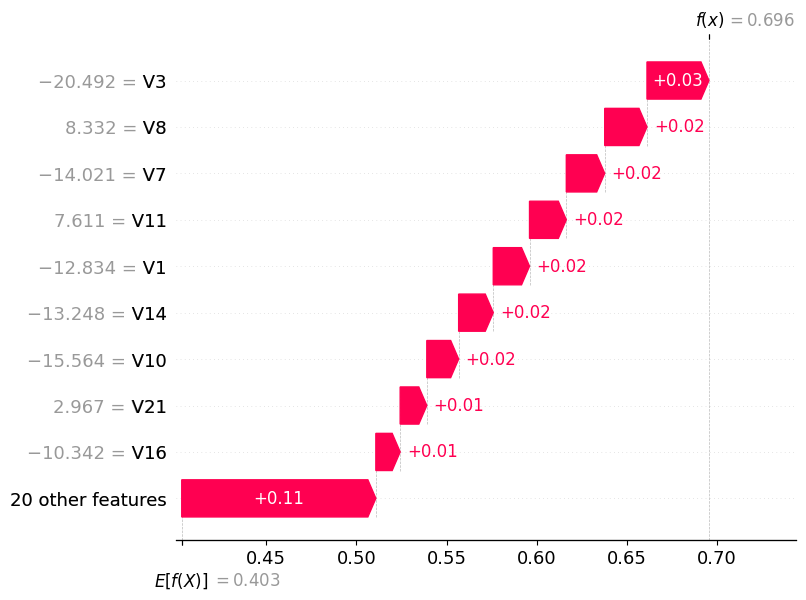


FP — Transaction 125478
Anomaly score: 0.642623
Decision threshold: 0.639208


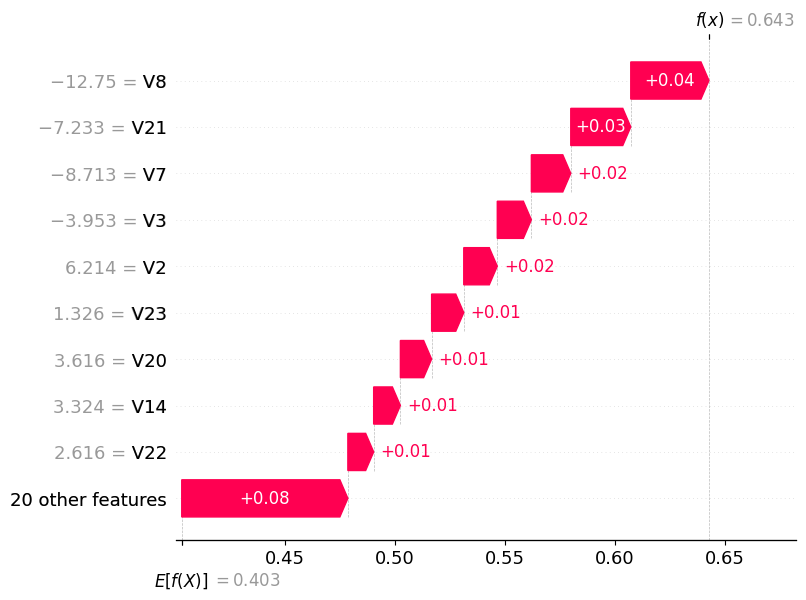


FP — Transaction 284281
Anomaly score: 0.655429
Decision threshold: 0.639208


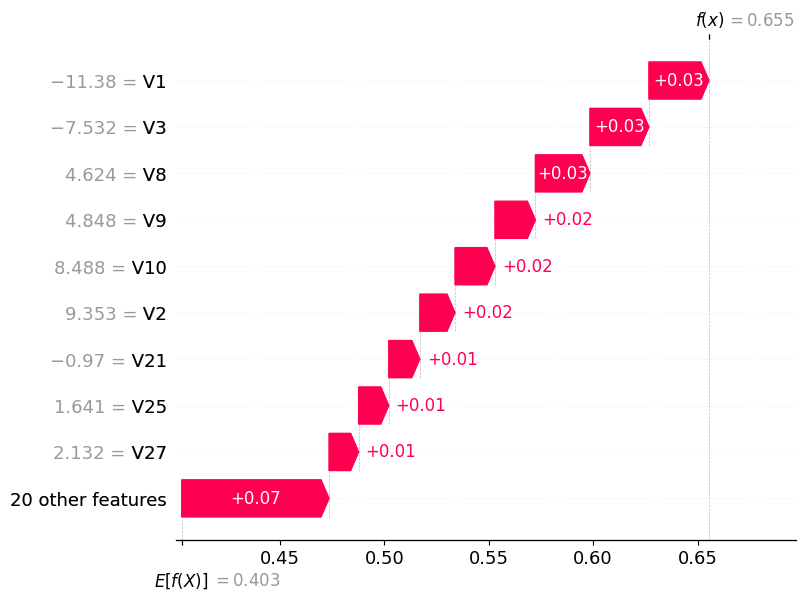


FN — Transaction 203700
Anomaly score: 0.540093
Decision threshold: 0.639208


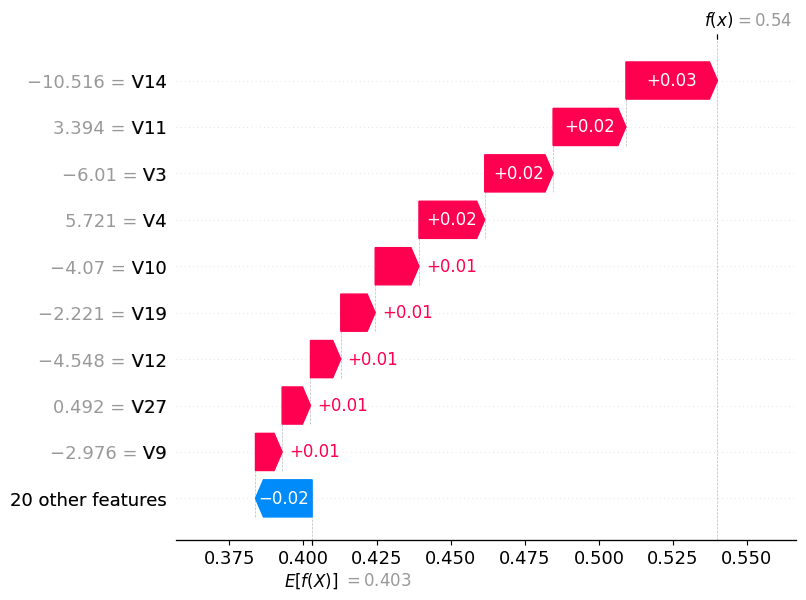


FN — Transaction 6899
Anomaly score: 0.615899
Decision threshold: 0.639208


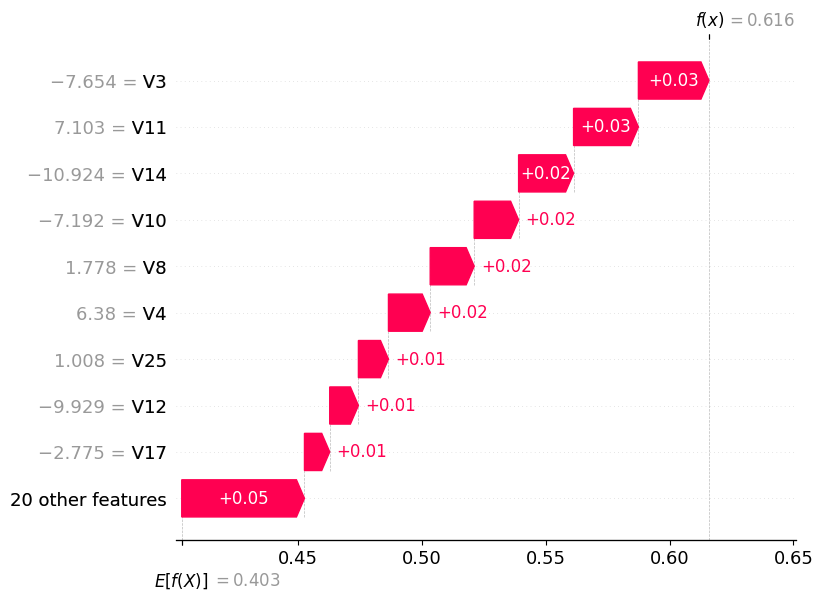

Exported categories: ['FN', 'FP', 'TP']


In [33]:

# Visualisation des six transactions
for i, ligne in df_selection_shap_credit.iterrows():

    print(
        f"\n{ligne['Catégorie']} — "
        f"Transaction {ligne['Indice original']}"
    )

    print(f"Score IF : {ligne['Score IF']:.6f}")
    print(f"Seuil IF : {seuil_if_shap_credit:.6f}")

   
# Create the output directory
figure_dir = PROJECT_ROOT / "figures" / "credit_card"
figure_dir.mkdir(parents=True, exist_ok=True)

# Export one representative example per category
exported_categories = set()

for i, row in df_selection_shap_credit.iterrows():

    category = row["Catégorie"]

    print(
        f"\n{category} — "
        f"Transaction {row['Indice original']}"
    )

    print(f"Anomaly score: {row['Score IF']:.6f}")
    print(f"Decision threshold: {seuil_if_shap_credit:.6f}")

    # Generate SHAP waterfall plot
    shap.plots.waterfall(
        shap_values_credit[i],
        max_display=10,
        show=False
    )

    fig = plt.gcf()

    # Save the first example of each category
    if category in {"TP", "FP", "FN"} and category not in exported_categories:

        fig.savefig(
            figure_dir / f"shap_{category.lower()}.png",
            dpi=200,
            bbox_inches="tight"
        )

        exported_categories.add(category)

    plt.show()
    plt.close(fig)

print("Exported categories:", sorted(exported_categories))



**Observation:** The background anomaly score is approximately **0.403**. Detected frauds and false alerts both exceed the Isolation Forest threshold (approximately **0.6392**), whereas missed frauds score below it.

This distinction demonstrates an important limitation: **statistically anomalous behavior is not synonymous with fraud**. SHAP explains the Isolation Forest decision but does not establish a causal link to fraudulent activity.

### 10.5 Comparing Feature Contributions Across Error Types

For each category (TP, FP, and FN), we compute the mean **absolute** SHAP contribution of each feature and list the top five. Absolute contributions describe **magnitude**, not whether a feature increases or decreases the score.

In [34]:

# Contributions SHAP moyennes absolues par catégorie
resultats_contributions_shap_credit = []

for categorie in ["TP", "FP", "FN"]:

    masque = (
        df_selection_shap_credit["Catégorie"].to_numpy()
        == categorie
    )

    contributions = np.abs(
        shap_values_credit.values[masque]
    ).mean(axis=0)

    for variable, contribution in zip(
        X_shap_credit.columns,
        contributions
    ):
        resultats_contributions_shap_credit.append({
            "Catégorie": categorie,
            "Variable": variable,
            "Contribution moyenne absolue": contribution
        })

df_contributions_shap_credit = pd.DataFrame(
    resultats_contributions_shap_credit
)

# Cinq variables principales par catégorie
top_contributions_shap_credit = (
    df_contributions_shap_credit
    .sort_values(
        "Contribution moyenne absolue",
        ascending=False
    )
    .groupby("Catégorie")
    .head(5)
    .sort_values(
        ["Catégorie", "Contribution moyenne absolue"],
        ascending=[True, False]
    )
)

display(top_contributions_shap_credit.round(4))


,Catégorie,Variable,Contribution moyenne absolue
71,FN,V14,0.0266
60,FN,V3,0.0258
68,FN,V11,0.0254
61,FN,V4,0.0195
67,FN,V10,0.0164
36,FP,V8,0.0308
31,FP,V3,0.0219
49,FP,V21,0.0211
29,FP,V1,0.0196
30,FP,V2,0.0160


### 10.6 SHAP Findings and Interpretation Limits

**Most influential features among the six inspected transactions:**

- **TP:** `V3`, `V8`, `V11`, `V14`, `V7`.
- **FP:** `V8`, `V3`, `V21`, `V1`, `V2`.
- **FN:** `V14`, `V3`, `V11`, `V4`, `V10`.

`V3` appears among the top five in all three categories. However, the anonymized `V1`–`V28` features have no directly interpretable business meaning, and the analysis uses **just six transactions and a 50-row background**.

**Conclusion:** SHAP improves the transparency of Isolation Forest anomaly scoring, but cannot determine whether an alert is a genuine fraud or establish causality.

## 11. Key Findings and Project Limitations

### Main Results

- **Supervised ranking:** Standard Logistic Regression (`C=0.1`) reaches the highest validation AP in the initial comparison (**0.7417**), but AP alone does not determine the preferred operating threshold.
- **Selected operational model:** Logistic Regression with RandomOverSampler (`C=1.0`) is selected using **maximum validation recall subject to precision ≥ 80%**, with a decision threshold of approximately **0.999991527267**.
- **Held-out Test:** The frozen selected model detects **69 of 95 frauds** with **18 false alerts** and **26 missed frauds** (precision **79.31%**, recall **72.63%**, F1 **0.7582**). Test precision falls slightly below the validation requirement.
- **Exploratory unsupervised comparison:** ECOD performs better than Isolation Forest and LOF on the reported **validation F1** among the unsupervised methods but **none satisfies the 80% precision constraint**; ECOD also deteriorates on Test.
- **Explainability:** Permutation SHAP clarifies which anonymized features drive a handful of Isolation Forest anomaly scores, including both genuine fraud alerts and false alarms.

### Limitations and Next Steps

1. **No temporal holdout:** Group-aware random splitting does not establish future transaction performance or robustness to concept drift.
2. **Rare positive class:** Small differences in the number of detected frauds can materially affect precision and recall.
3. **Validation vs Test:** A threshold that satisfies 80% precision on validation is **not guaranteed** to satisfy it on unseen data.
4. **Unsupervised ≠ fraud-specific:** Anomaly detectors identify statistical rarity, not necessarily fraudulent behavior.
5. **Interpretability scope:** PCA-derived `V1`–`V28` features are anonymized; six SHAP cases are illustrative, not population-wide explanations.
6. **Exploratory additions:** ECOD and SHAP were analyzed after the main test; they should not be used to retrospectively revise or overclaim the frozen model's generalization.

**Overall conclusion:** This project demonstrates a reproducible end-to-end fraud-detection evaluation workflow, from leakage-aware preprocessing and class-imbalance strategies to constraint-based threshold selection, independent test assessment, and error analysis. It also illustrates why ranking metrics, alert quality, and real-world deployment constraints must be considered together.

In [35]:

output_dir = PROJECT_ROOT / "results" / "credit_card"
output_dir.mkdir(parents=True, exist_ok=True)

df_scores_credit.to_csv(
    output_dir / "validation_model_comparison.csv", index=False
)

df_final_credit.to_csv(
    output_dir / "final_test_results.csv", index=False
)

df_comparaison_non_supervisee_credit.to_csv(
    output_dir / "unsupervised_comparison.csv", index=False
)


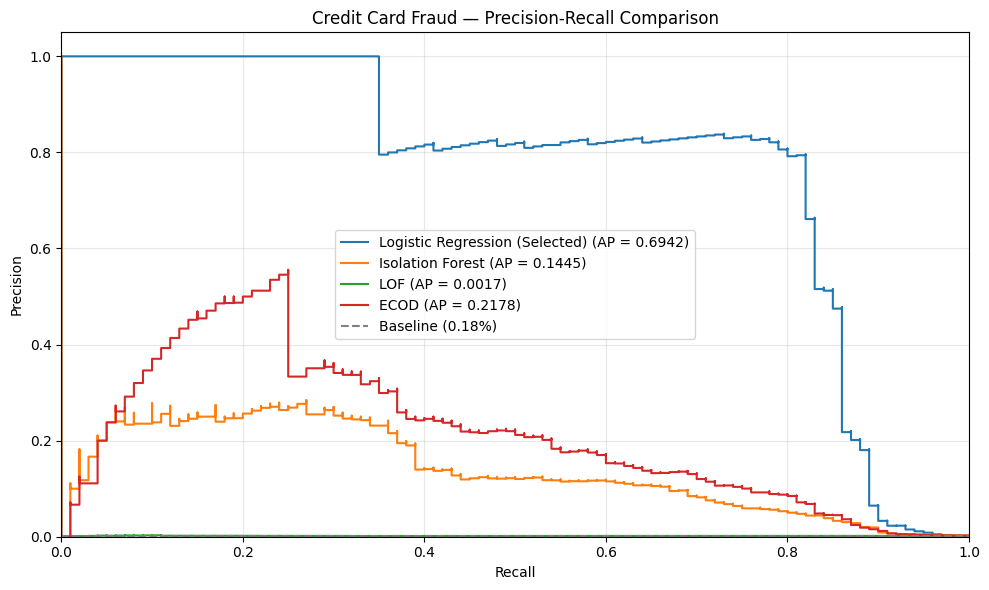

In [36]:

from sklearn.metrics import precision_recall_curve, average_precision_score

# Validation scores for the selected models
models_pr = {
    "Logistic Regression (Selected)": scores_validation_credit[nom_retenu_credit],
    "Isolation Forest": scores_if_credit,
    "LOF": scores_lof_credit,
    "ECOD": scores_val_ecod_credit
}

fig, ax = plt.subplots(figsize=(10, 6))

# Precision-Recall curves
for name, scores in models_pr.items():
    precision, recall, _ = precision_recall_curve(
        y_val_credit, scores
    )

    ap = average_precision_score(y_val_credit, scores)

    ax.step(
        recall[::-1],
        precision[::-1],
        where="post",
        label=f"{name} (AP = {ap:.4f})"
    )

# Baseline: fraud prevalence
baseline = y_val_credit.mean()

ax.axhline(
    baseline,
    color="gray",
    linestyle="--",
    label=f"Baseline ({baseline:.2%})"
)

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Credit Card Fraud — Precision-Recall Comparison")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.05)
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()

# Export
figure_dir = PROJECT_ROOT / "figures" / "credit_card"
figure_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figure_dir / "precision_recall_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()



**Observation:**

Precision-Recall curves compare the ability of supervised and unsupervised models to identify fraudulent transactions.

Average Precision (AP) summarizes performance across decision thresholds and is particularly informative for highly imbalanced datasets.

The selected Logistic Regression model provides stronger fraud detection performance than the unsupervised alternatives.

All results shown here are based on the validation set. The final test set remains separate from model and threshold selection.
